In [127]:
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)

print("\nEnvironment setup successful!")

Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1
XGBoost: 3.4.1

Environment setup successful!


In [128]:
columns = (
    ['unit_number', 'time_in_cycles']
    + [f'op_setting_{i}' for i in range(1, 4)]
    + [f'sensor_{i}' for i in range(1, 22)]
)

In [129]:
DATA_PATH = "../data/"

# FD001
train_fd001 = pd.read_csv(DATA_PATH + "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_fd001 = pd.read_csv(DATA_PATH + "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_fd001 = pd.read_csv(DATA_PATH + "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# FD002
train_fd002 = pd.read_csv(DATA_PATH + "train_FD002.txt", sep=r"\s+", header=None, names=columns)
test_fd002 = pd.read_csv(DATA_PATH + "test_FD002.txt", sep=r"\s+", header=None, names=columns)
rul_fd002 = pd.read_csv(DATA_PATH + "RUL_FD002.txt", sep=r"\s+", header=None, names=["RUL"])

In [130]:
datasets = {
    "FD001 Train": train_fd001,
    "FD001 Test": test_fd001,
    "FD001 RUL": rul_fd001,
    "FD002 Train": train_fd002,
    "FD002 Test": test_fd002,
    "FD002 RUL": rul_fd002
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

FD001 Train: (20631, 26)
FD001 Test: (13096, 26)
FD001 RUL: (100, 1)
FD002 Train: (53759, 26)
FD002 Test: (33991, 26)
FD002 RUL: (259, 1)


In [131]:
def validate_dataset(df, name):

    print(f"\n{'='*40}")
    print(f"Dataset: {name}")
    print(f"{'='*40}")

    print("Shape:", df.shape)
    print("Columns:", len(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("Unique engines:", df['unit_number'].nunique()
          if 'unit_number' in df.columns else "N/A")

    print("Data types:")
    print(df.dtypes.value_counts())

for name, df in datasets.items():
    validate_dataset(df, name)


Dataset: FD001 Train
Shape: (20631, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD001 Test
Shape: (13096, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD001 RUL
Shape: (100, 1)
Columns: 1
Missing values: 0
Duplicate rows: 29
Unique engines: N/A
Data types:
int64    1
Name: count, dtype: int64

Dataset: FD002 Train
Shape: (53759, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 260
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD002 Test
Shape: (33991, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 259
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD002 RUL
Shape: (259, 1)
Columns: 1
Missing values: 0
Duplicate rows: 127
Unique engines: N/A
Data types:
int64    1
Name: count, dtype: i

========================================
Dataset: FD001 Train
========================================
Shape: (20631, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Data types:
float64    22
int64       4
Name: count, dtype: int64

========================================
Dataset: FD001 Test
========================================
Shape: (13096, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Data types:
float64    22
int64       4
Name: count, dtype: int64

========================================
Dataset: FD001 RUL
========================================
Shape: (100, 1)
Columns: 1
Missing values: 0
Duplicate rows: 29
Unique engines: N/A
Data types:
int64    1
Name: count, dtype: int64

========================================
Dataset: FD002 Train
========================================
Shape: (53759, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 260
Data types:
float64    22
int64       4
Name: count, dtype: int64

========================================
Dataset: FD002 Test
========================================
Shape: (33991, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 259
Data types:
float64    22
int64       4
Name: count, dtype: int64

========================================
Dataset: FD002 RUL
========================================
Shape: (259, 1)
Columns: 1
Missing values: 0
Duplicate rows: 127
Unique engines: N/A
Data types:
int64    1
Name: count, dtype: int64

In [132]:
print("FD001 Test engines:", test_fd001['unit_number'].nunique())
print("FD001 RUL records:", len(rul_fd001))

print("FD002 Test engines:", test_fd002['unit_number'].nunique())
print("FD002 RUL records:", len(rul_fd002))

FD001 Test engines: 100
FD001 RUL records: 100
FD002 Test engines: 259
FD002 RUL records: 259


In [133]:
fd001_stats = train_fd001.describe().T

fd002_stats = train_fd002.describe().T

display(fd001_stats)
display(fd002_stats)

,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
time_in_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


,count,mean,std,min,25%,50%,75%,max
unit_number,53759.0,131.082981,74.463862,1.0000,68.0000,131.0000,195.0000,260.0000
time_in_cycles,53759.0,109.154746,69.180569,1.0000,52.0000,104.0000,157.0000,378.0000
op_setting_1,53759.0,23.998407,14.747376,0.0000,10.0046,25.0013,41.9980,42.0080
op_setting_2,53759.0,0.572056,0.310016,0.0000,0.2507,0.7000,0.8400,0.8420
op_setting_3,53759.0,94.046020,14.237735,60.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,53759.0,472.910207,26.389707,445.0000,445.0000,462.5400,491.1900,518.6700
sensor_2,53759.0,579.672399,37.289399,535.5300,549.5700,555.9800,607.3400,644.5200
sensor_3,53759.0,1419.971013,105.946341,1243.7300,1352.7600,1369.1800,1499.3700,1612.8800
sensor_4,53759.0,1205.442024,119.123428,1023.7700,1123.6550,1138.8900,1306.8500,1439.2300
sensor_5,53759.0,8.031986,3.613839,3.9100,3.9100,7.0500,10.5200,14.6200


In [134]:
sensor_columns = [
    col for col in train_fd001.columns
    if col.startswith('sensor_')
]

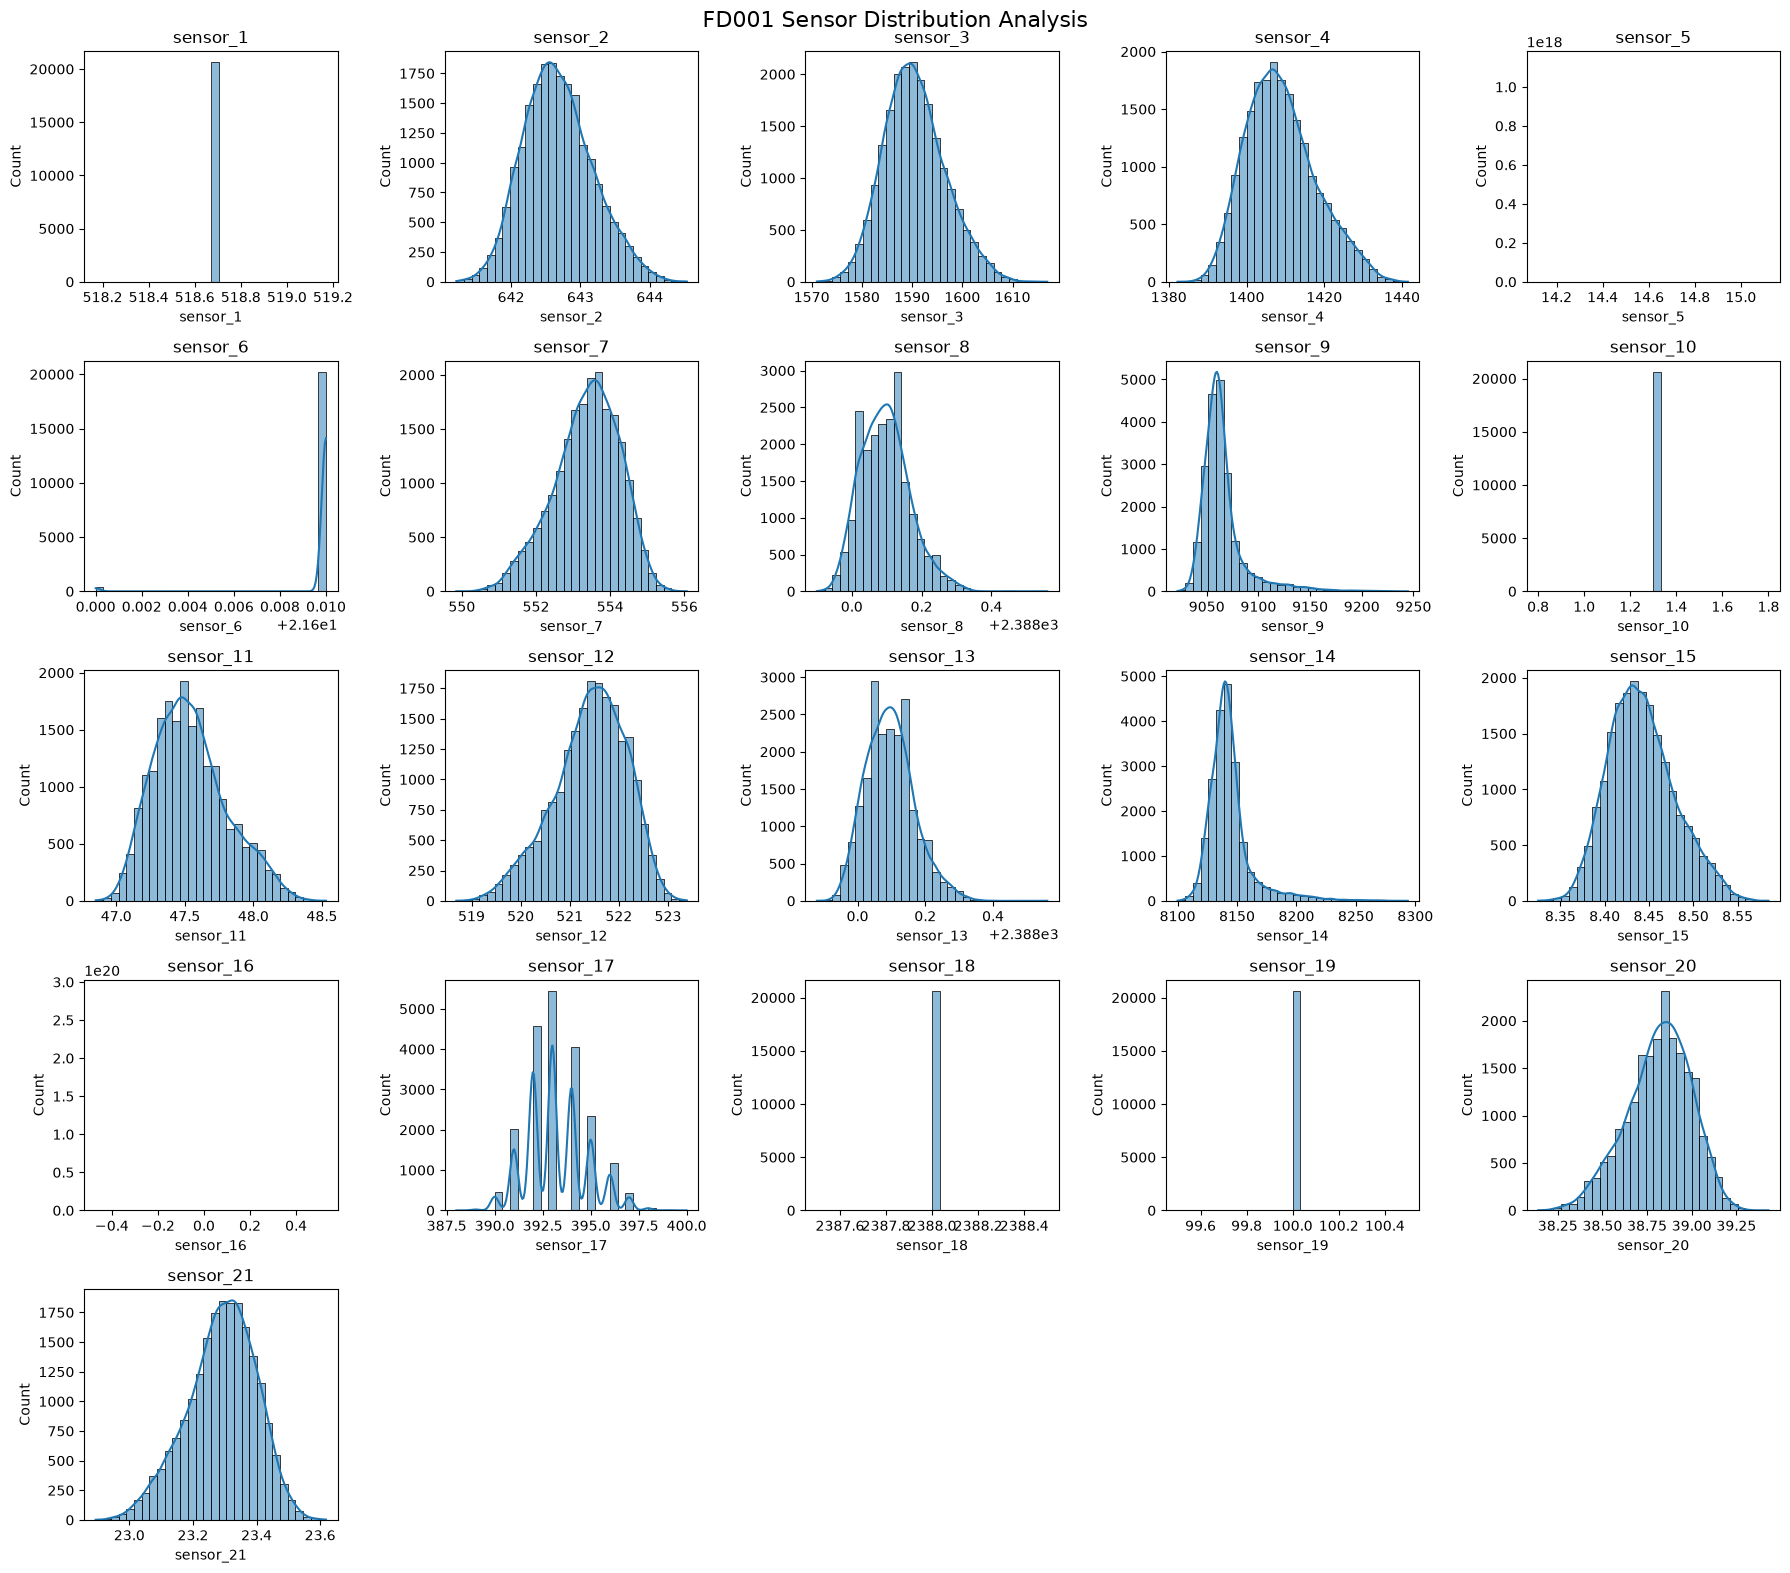

In [135]:
#FD001 sensor distributions
fig, axes = plt.subplots(5, 5, figsize=(18, 16))

for i, col in enumerate(sensor_columns):

    sns.histplot(
        data=train_fd001,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i // 5, i % 5]
    )

    axes[i // 5, i % 5].set_title(col)

for i in range(len(sensor_columns), 25):
    axes[i // 5, i % 5].set_visible(False)

plt.suptitle(
    "FD001 Sensor Distribution Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [136]:
for name, df in {
    "FD001": train_fd001,
}.items():

    constant = [
        col for col in df.columns
        if df[col].nunique() <= 1
    ]

    print(f"{name} constant columns:")
    print(constant)

FD001 constant columns:
['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


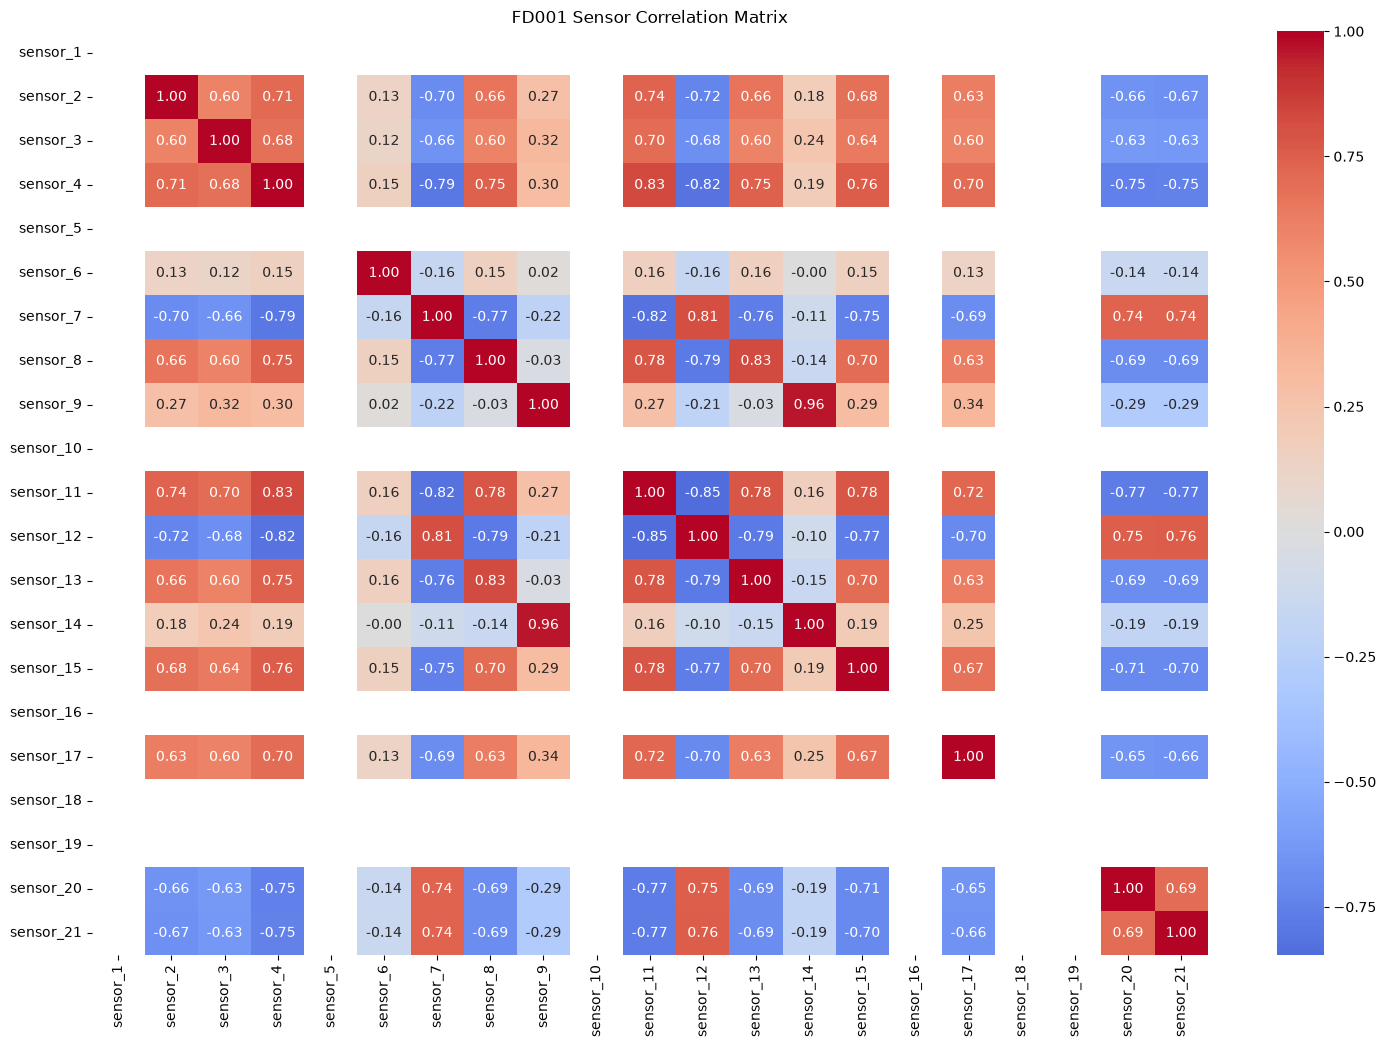

In [137]:
#corellation analysis for FD001
sensor_columns = [
    col for col in train_fd001.columns
    if col.startswith('sensor_')
]

correlation_fd001 = train_fd001[sensor_columns].corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_fd001,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title("FD001 Sensor Correlation Matrix")
plt.show()

In [138]:
# FD001 engine lifecycle
fd001_life = (
    train_fd001.groupby('unit_number')['time_in_cycles']
    .max()
)


In [139]:
fd002_life = (
    train_fd002.groupby('unit_number')['time_in_cycles'].max()
)


In [140]:
print(fd001_life.head(10))

unit_number
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: time_in_cycles, dtype: int64


In [141]:
print("FD001 Engine Lifespan:")
print(fd001_life.describe())

FD001 Engine Lifespan:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: time_in_cycles, dtype: float64


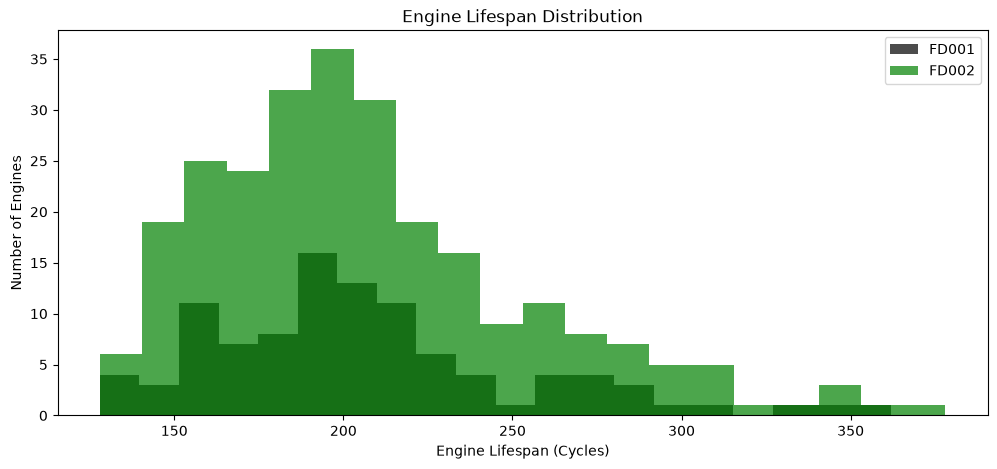

In [142]:
plt.figure(figsize=(12, 5))

plt.hist(fd001_life, bins=20, alpha=0.7, label='FD001', color='black')
plt.hist(fd002_life, bins=20, alpha=0.7, label='FD002', color='green')

plt.xlabel('Engine Lifespan (Cycles)')
plt.ylabel('Number of Engines')
plt.title('Engine Lifespan Distribution')
plt.legend()
plt.show()

In [143]:
# Analyze the data for a specific engine
engine_1 = train_fd001[
    train_fd001['unit_number'] == 1
]

engine_1.head()

,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


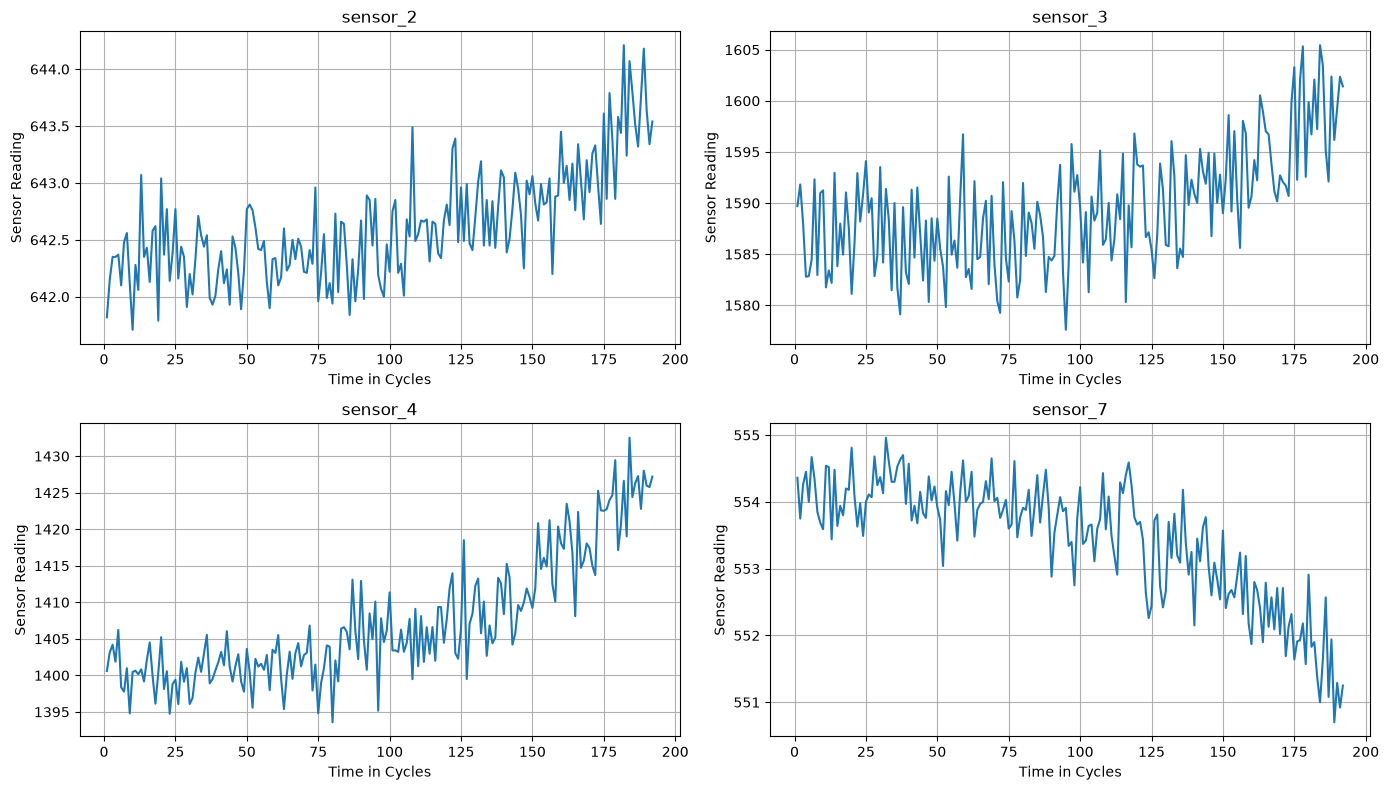

In [144]:
# Visualize sensor readings over time for engine 1
sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for sensor, ax in zip(sensors, axes.flatten()):
    ax.plot(
        engine_1['time_in_cycles'],
        engine_1[sensor]
    )
    ax.set_title(sensor)
    ax.set_xlabel('Time in Cycles')
    ax.set_ylabel('Sensor Reading')
    ax.grid(True)

plt.tight_layout()
plt.show()

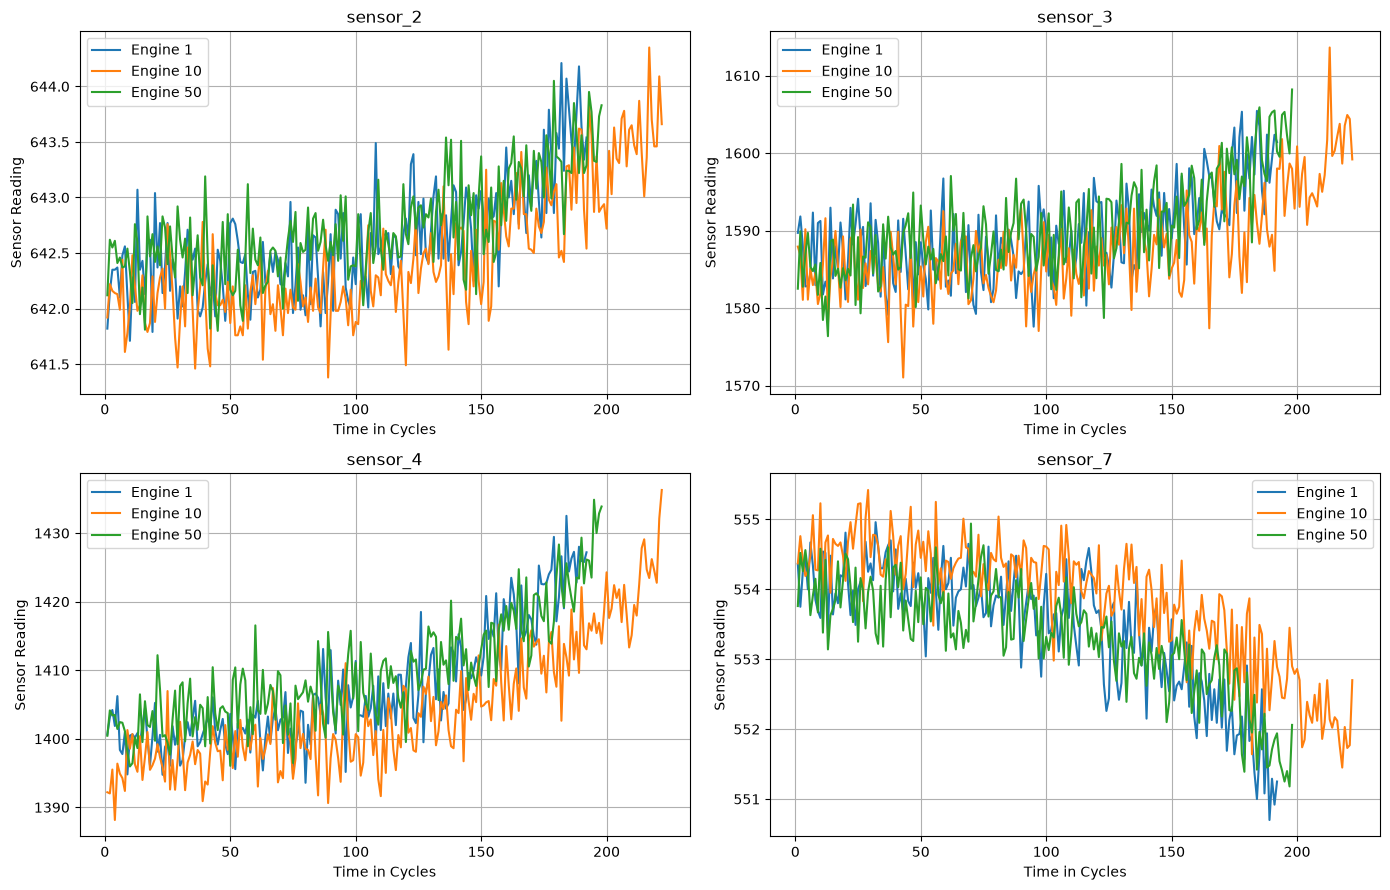

In [145]:
# Visualize sensor readings over time for multiple engines
selected_engines = [1, 10, 50]
sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for sensor, ax in zip(sensors, axes.flatten()):

    for engine_id in selected_engines:

        engine_data = train_fd001[
            train_fd001['unit_number'] == engine_id
        ]

        ax.plot(
            engine_data['time_in_cycles'],
            engine_data[sensor],
            label=f'Engine {engine_id}'
        )

    ax.set_title(sensor)
    ax.set_xlabel('Time in Cycles')
    ax.set_ylabel('Sensor Reading')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

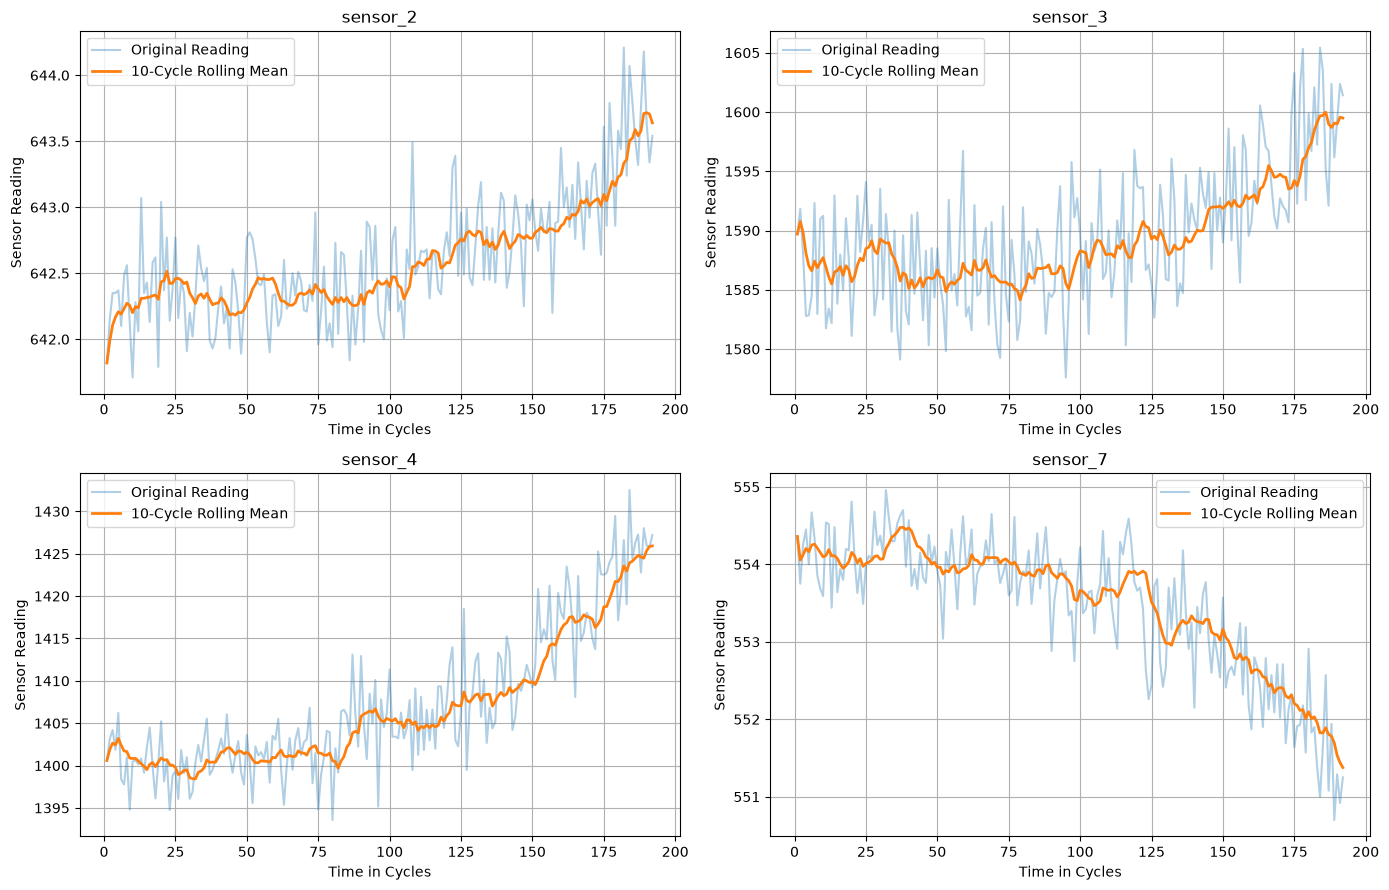

In [ ]:
#We use a 10-cycle rolling mean to smooth sensor readings and understand the overall trend more clearly.

engine_1 = train_fd001[
    train_fd001['unit_number'] == 1
].copy()

sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for sensor, ax in zip(sensors, axes.flatten()):

    rolling_mean = engine_1[sensor].rolling(
        window=10,
        min_periods=1
    ).mean()

    ax.plot(
        engine_1['time_in_cycles'],
        engine_1[sensor],
        alpha=0.35,
        label='Original Reading'
    )

    ax.plot(
        engine_1['time_in_cycles'],
        rolling_mean,
        linewidth=2,
        label='10-Cycle Rolling Mean'
    )

    ax.set_title(sensor)
    ax.set_xlabel('Time in Cycles')
    ax.set_ylabel('Sensor Reading')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [147]:
fd001 = train_fd001.copy()

fd001['RUL'] = (
    fd001.groupby('unit_number')['time_in_cycles'].transform('max')
    - fd001['time_in_cycles']
)

print(fd001[['unit_number', 'time_in_cycles', 'RUL']].head(10))

   unit_number  time_in_cycles  RUL
0            1               1  191
1            1               2  190
2            1               3  189
3            1               4  188
4            1               5  187
5            1               6  186
6            1               7  185
7            1               8  184
8            1               9  183
9            1              10  182


In [148]:
sensor_columns = [
    col for col in fd001.columns
    if col.startswith('sensor_')
]

rul_correlation = (
    fd001[sensor_columns + ['RUL']]
    .corr()['RUL']
    .drop('RUL')
    .sort_values()
)

print(rul_correlation)

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64


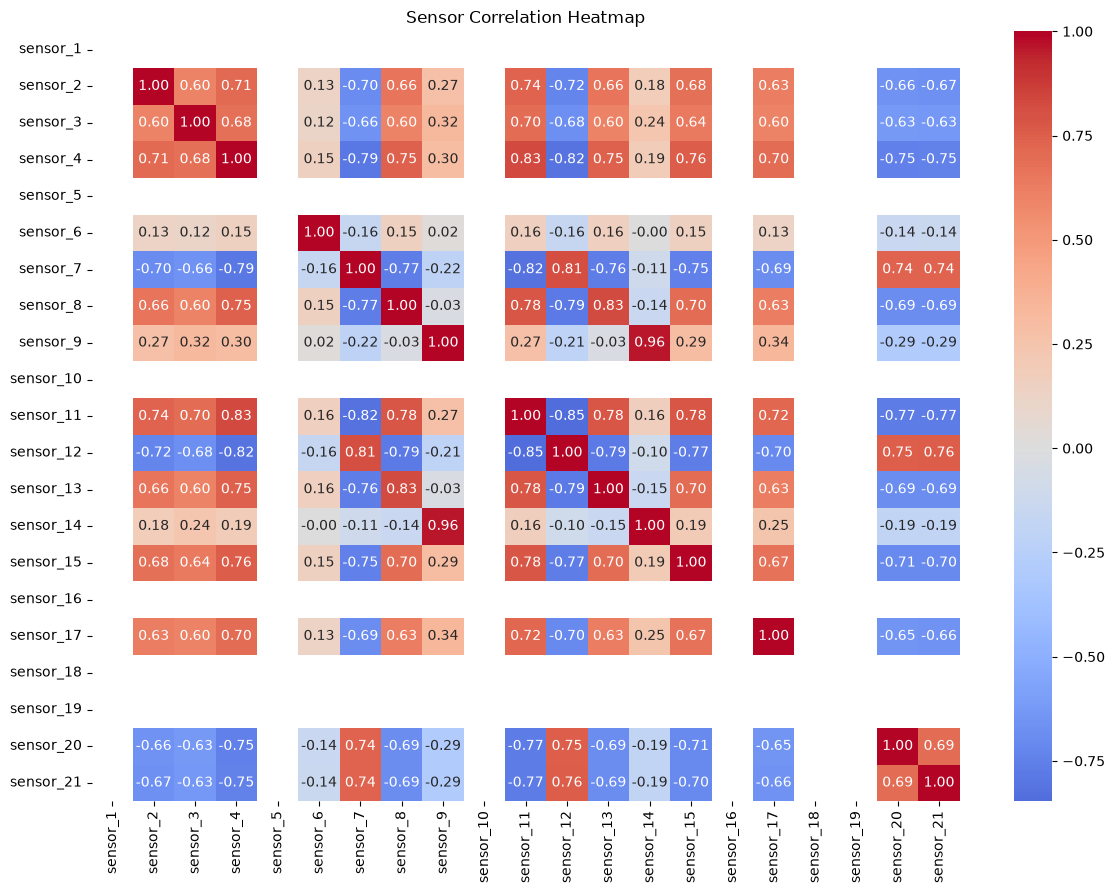

In [149]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select sensor columns
sensor_corr = df[sensor_columns].corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    sensor_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title("Sensor Correlation Heatmap")
plt.show()

In [150]:
#Feature Engineering
# Identify constant sensor columns

constant_features = [
    col for col in sensor_columns
    if df[col].nunique(dropna=True) <= 1
]

print("Constant Features:")
print(constant_features)

Constant Features:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [151]:
corr_matrix = df[sensor_columns].corr()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Sensor_1',
    'Sensor_2',
    'Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Correlation'].abs() >= 0.95
]

print(high_corr_pairs.sort_values(
    by='Correlation',
    key=abs,
    ascending=False
))

     Sensor_1   Sensor_2  Correlation
181  sensor_9  sensor_14     0.963157


In [152]:
print(df.columns.tolist())

['unit_number', 'time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [153]:
# Create FD001 training DataFrame
df_fd001 = train_fd001.copy()

# Calculate maximum cycle for each engine
df_fd001['max_cycle'] = (
    df_fd001.groupby('unit_number')['time_in_cycles']
    .transform('max')
)

# Calculate Remaining Useful Life
df_fd001['RUL'] = (
    df_fd001['max_cycle'] - df_fd001['time_in_cycles']
)

# Display results
print(
    df_fd001[
        ['unit_number', 'time_in_cycles', 'max_cycle', 'RUL']
    ].head(10)
)


   unit_number  time_in_cycles  max_cycle  RUL
0            1               1        192  191
1            1               2        192  190
2            1               3        192  189
3            1               4        192  188
4            1               5        192  187
5            1               6        192  186
6            1               7        192  185
7            1               8        192  184
8            1               9        192  183
9            1              10        192  182


In [154]:

# Target variable
y_fd001 = df_fd001['RUL']

# Select features
feature_columns_fd001 = (
    ['time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3']
    + [
        col for col in sensor_columns
        if col not in constant_features
    ]
)

# Feature matrix
X_fd001 = df_fd001[feature_columns_fd001].copy()

# Verify dimensions
print("Feature shape:", X_fd001.shape)
print("Target shape:", y_fd001.shape)
print("Number of features:", len(feature_columns_fd001))

print("\nSelected features:")
print(feature_columns_fd001)


Feature shape: (20631, 19)
Target shape: (20631,)
Number of features: 19

Selected features:
['time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [155]:
# Identify sensor and operating-setting columns
sensor_columns = [
    col for col in df_fd001.columns
    if col.startswith('sensor_')
]

operation_columns = [
    'op_setting_1',
    'op_setting_2',
    'op_setting_3'
]

candidate_features = operation_columns + sensor_columns

# Find constant features
constant_features = [
    col for col in candidate_features
    if df_fd001[col].nunique() <= 1
]

print("Constant features:", constant_features)
print("Number of constant features:", len(constant_features))

Constant features: ['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Number of constant features: 7


In [156]:
# Create a separate processed test dataset
test_fd001_processed = test_fd001.copy()

# Map official RUL values to engine IDs
rul_mapping_fd001 = dict(
    zip(
        range(1, len(rul_fd001) + 1),
        rul_fd001['RUL']
    )
)

test_fd001_processed['RUL_final'] = (
    test_fd001_processed['unit_number'].map(rul_mapping_fd001)
)

# Maximum observed cycle per engine
test_fd001_processed['max_cycle'] = (
    test_fd001_processed.groupby('unit_number')['time_in_cycles']
    .transform('max')
)

# Calculate actual RUL
test_fd001_processed['RUL'] = (
    test_fd001_processed['RUL_final']
    + test_fd001_processed['max_cycle']
    - test_fd001_processed['time_in_cycles']
)

# Apply cap
test_fd001_processed['RUL_cap125'] = (
    test_fd001_processed['RUL'].clip(upper=125)
)

# Test target
y_test_fd001 = test_fd001_processed['RUL_cap125']

print("Missing RUL values:", y_test_fd001.isna().sum())
print("Test records:", len(y_test_fd001))
print("Test engines:", test_fd001_processed['unit_number'].nunique())

print(test_fd001_processed[
    ['unit_number', 'time_in_cycles', 'RUL', 'RUL_cap125']
].head(10))

Missing RUL values: 0
Test records: 13096
Test engines: 100
   unit_number  time_in_cycles  RUL  RUL_cap125
0            1               1  142         125
1            1               2  141         125
2            1               3  140         125
3            1               4  139         125
4            1               5  138         125
5            1               6  137         125
6            1               7  136         125
7            1               8  135         125
8            1               9  134         125
9            1              10  133         125


In [157]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X_fd001,
        y_fd001,
        groups=df_fd001['unit_number']
    )
)

# Split features
X_train = X_fd001.iloc[train_idx]
X_val = X_fd001.iloc[val_idx]

# Split target
y_train = y_fd001.iloc[train_idx]
y_val = y_fd001.iloc[val_idx]

In [158]:
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

print(
    "Training engines:",
    df_fd001.iloc[train_idx]['unit_number'].nunique()
)

print(
    "Validation engines:",
    df_fd001.iloc[val_idx]['unit_number'].nunique()
)

Training data: (16561, 19)
Validation data: (4070, 19)
Training engines: 80
Validation engines: 20


In [159]:

from xgboost import XGBRegressor

model_fd001 = XGBRegressor(
    n_estimators=700,
    learning_rate=0.01,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=5,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train model
model_fd001.fit(X_train, y_train)

print("FD001 XGBoost model training completed!")


FD001 XGBoost model training completed!


In [160]:
y_pred = model_fd001.predict(X_val)

print("Actual RUL:", y_val.values[:10])
print("Predicted RUL:", y_pred[:10])

Actual RUL: [191 190 189 188 187 186 185 184 183 182]
Predicted RUL: [217.70486 209.92078 215.06567 229.79935 228.70387 222.97578 218.60934
 213.37303 200.07751 193.69923]


In [161]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate validation predictions
y_pred_fd001 = model_fd001.predict(X_val_fd001)

# Calculate metrics
mae_fd001 = mean_absolute_error(y_val_fd001, y_pred_fd001)

rmse_fd001 = np.sqrt(
    mean_squared_error(y_val_fd001, y_pred_fd001)
)

r2_fd001 = r2_score(y_val_fd001, y_pred_fd001)

# Display results
print("FD001 Validation Results")
print("------------------------")
print(f"MAE  : {mae_fd001:.4f}")
print(f"RMSE : {rmse_fd001:.4f}")
print(f"R2   : {r2_fd001:.4f}")

FD001 Validation Results
------------------------
MAE  : 23.2432
RMSE : 30.5122
R2   : 0.7840


In [162]:
import pandas as pd

feature_importance_fd001 = pd.DataFrame({
    'Feature': feature_columns_fd001,
    'Importance': model_fd001.feature_importances_
})

feature_importance_fd001 = feature_importance_fd001.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance_fd001)

           Feature  Importance
0   time_in_cycles    0.417214
11       sensor_11    0.214240
6         sensor_4    0.061866
10        sensor_9    0.041617
12       sensor_12    0.035921
14       sensor_14    0.026965
8         sensor_7    0.026960
15       sensor_15    0.021441
9         sensor_8    0.020293
13       sensor_13    0.017925
18       sensor_21    0.017703
17       sensor_20    0.015315
4         sensor_2    0.014764
5         sensor_3    0.014584
7         sensor_6    0.014019
16       sensor_17    0.013790
1     op_setting_1    0.013050
2     op_setting_2    0.012333
3     op_setting_3    0.000000


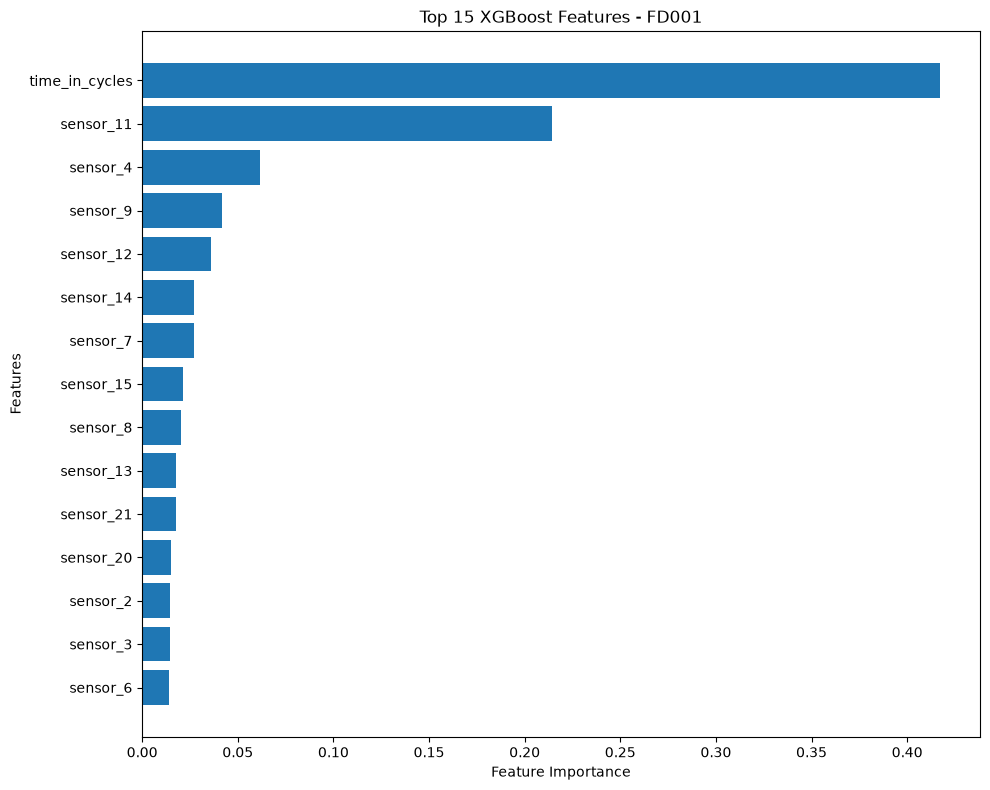

In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

top_features = feature_importance_fd001.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 XGBoost Features - FD001")

plt.tight_layout()
plt.show()

In [164]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm_fd001 = permutation_importance(
    model_fd001,
    X_val_fd001,
    y_val_fd001,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

perm_importance_fd001 = pd.DataFrame({
    'Feature': X_val_fd001.columns,
    'Importance': perm_fd001.importances_mean,
    'Std': perm_fd001.importances_std
})

perm_importance_fd001 = perm_importance_fd001.sort_values(
    by='Importance',
    ascending=False
)

print(perm_importance_fd001)

           Feature  Importance       Std
0   time_in_cycles   19.178848  0.326684
11       sensor_11    4.147204  0.107478
6         sensor_4    1.877516  0.071725
12       sensor_12    1.730502  0.046518
10        sensor_9    1.486325  0.095888
15       sensor_15    1.128438  0.038059
8         sensor_7    0.882027  0.043796
18       sensor_21    0.861392  0.084976
4         sensor_2    0.697513  0.046968
14       sensor_14    0.646136  0.119862
17       sensor_20    0.603766  0.032383
5         sensor_3    0.589538  0.021978
16       sensor_17    0.268450  0.016722
9         sensor_8    0.239704  0.058210
13       sensor_13    0.218077  0.032683
1     op_setting_1    0.007706  0.015441
7         sensor_6    0.006041  0.002178
3     op_setting_3    0.000000  0.000000
2     op_setting_2   -0.009127  0.028446


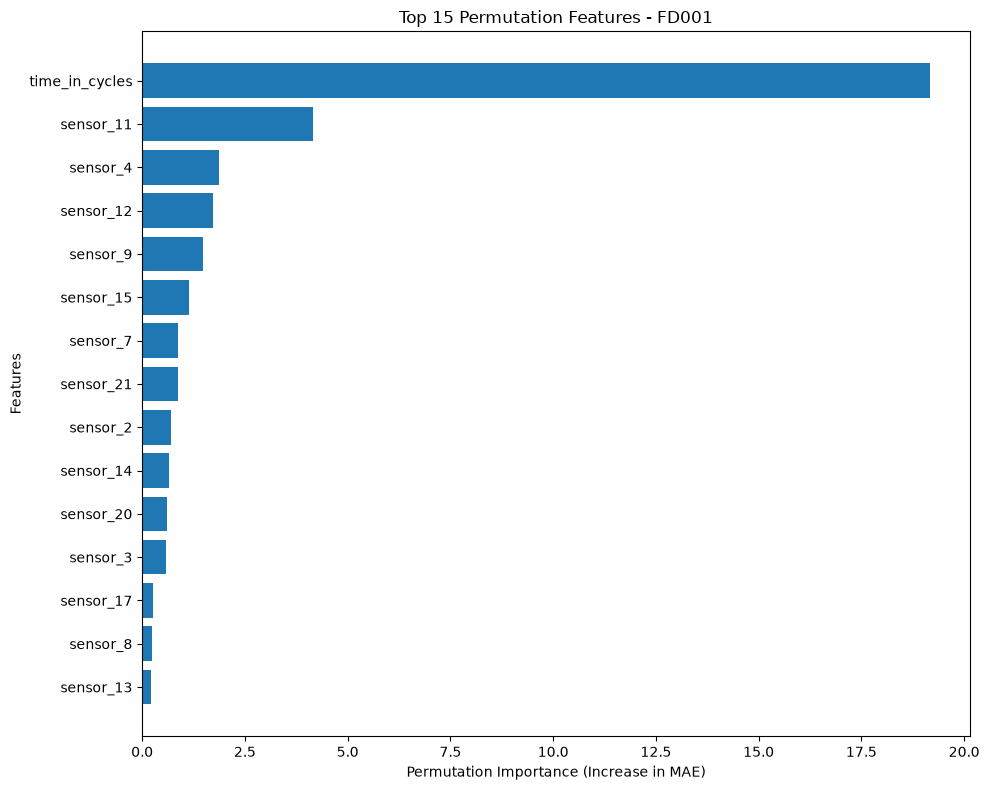

In [165]:
import matplotlib.pyplot as plt

top_perm_features = perm_importance_fd001.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_perm_features['Feature'],
    top_perm_features['Importance']
)

plt.xlabel("Permutation Importance (Increase in MAE)")
plt.ylabel("Features")
plt.title("Top 15 Permutation Features - FD001")

plt.tight_layout()
plt.show()

In [166]:
# Remove near-zero importance features
drop_features_fd001 = [
    'sensor_6',
    'op_setting_2'
]

selected_features_fd001 = [
    col for col in X_train_fd001.columns
    if col not in drop_features_fd001
]

# Prepare reduced datasets
X_train_reduced_fd001 = X_train_fd001[selected_features_fd001]
X_val_reduced_fd001 = X_val_fd001[selected_features_fd001]

print("Original features:", X_train_fd001.shape[1])
print("Reduced features:", X_train_reduced_fd001.shape[1])

print("Training shape:", X_train_reduced_fd001.shape)
print("Validation shape:", X_val_reduced_fd001.shape)

Original features: 19
Reduced features: 17
Training shape: (16561, 17)
Validation shape: (4070, 17)


In [167]:
from xgboost import XGBRegressor

reduced_model_fd001 = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train reduced model
reduced_model_fd001.fit(
    X_train_reduced_fd001,
    y_train_fd001
)

# Generate predictions
reduced_pred_fd001 = reduced_model_fd001.predict(
    X_val_reduced_fd001
)

print("Reduced FD001 model training completed!")

Reduced FD001 model training completed!


In [168]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Reduced model metrics
reduced_mae_fd001 = mean_absolute_error(
    y_val_fd001, reduced_pred_fd001
)

reduced_rmse_fd001 = np.sqrt(
    mean_squared_error(y_val_fd001, reduced_pred_fd001)
)

reduced_r2_fd001 = r2_score(
    y_val_fd001, reduced_pred_fd001
)

# Compare original and reduced models
print("FD001 Model Comparison")
print("----------------------")

print(f"Baseline MAE : {mae_fd001:.4f}")
print(f"Reduced MAE  : {reduced_mae_fd001:.4f}")

print(f"Baseline RMSE: {rmse_fd001:.4f}")
print(f"Reduced RMSE : {reduced_rmse_fd001:.4f}")

print(f"Baseline R2  : {r2_fd001:.4f}")
print(f"Reduced R2   : {reduced_r2_fd001:.4f}")

FD001 Model Comparison
----------------------
Baseline MAE : 23.2432
Reduced MAE  : 23.8199
Baseline RMSE: 30.5122
Reduced RMSE : 31.4186
Baseline R2  : 0.7840
Reduced R2   : 0.7710


In [169]:
# Training predictions
y_train_pred_fd001 = model_fd001.predict(X_train_fd001)

# Calculate MAE
train_mae_fd001 = mean_absolute_error(
    y_train_fd001, y_train_pred_fd001
)

val_mae_fd001 = mean_absolute_error(
    y_val_fd001, y_pred_fd001
)

print("FD001 Overfitting Check")
print("-----------------------")
print("Training MAE  :", round(train_mae_fd001, 4))
print("Validation MAE:", round(val_mae_fd001, 4))
print("MAE Gap       :", round(val_mae_fd001 - train_mae_fd001, 4))

FD001 Overfitting Check
-----------------------
Training MAE  : 18.1577
Validation MAE: 23.2432
MAE Gap       : 5.0856


In [171]:

from sklearn.metrics import mean_absolute_error

# Training predictions
y_train_pred_fd001 = model_fd001.predict(X_train)

# Validation predictions
y_val_pred_fd001 = model_fd001.predict(X_val)

# Calculate MAE
train_mae_fd001 = mean_absolute_error(
    y_train, y_train_pred_fd001
)

val_mae_fd001 = mean_absolute_error(
    y_val, y_val_pred_fd001
)

# Calculate difference
mae_gap_fd001 = val_mae_fd001 - train_mae_fd001

print("Training MAE:", round(train_mae_fd001, 4))
print("Validation MAE:", round(val_mae_fd001, 4))
print("MAE Gap:", round(mae_gap_fd001, 4))

# Check model fit
if train_mae_fd001 > 20 and val_mae_fd001 > 20:
    print("Possible Underfitting")
elif mae_gap_fd001 > 10:
    print("Possible Overfitting")
else:
    print("No strong sign of underfitting or overfitting")


Training MAE: 18.1577
Validation MAE: 23.2432
MAE Gap: 5.0856
No strong sign of underfitting or overfitting


In [172]:
# Check whether target columns are present in features
target_columns = ['RUL', 'RUL_cap125', 'RUL_final', 'max_cycle']
print("Data leakage check:")
leaked_columns = [
    col for col in X_train_fd001.columns
    if col in target_columns
]

print("Potential target leakage:", leaked_columns)

# Check engine overlap
train_engines = set(
    df_fd001.iloc[train_idx_fd001]['unit_number']
)

val_engines = set(
    df_fd001.iloc[val_idx_fd001]['unit_number']
)
print("Overlapping engines:", train_engines.intersection(val_engines))

Data leakage check:
Potential target leakage: []
Overlapping engines: set()


In [173]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    GroupKFold
)

In [174]:
param_grid_fd001 = {
    'n_estimators': [200, 300, 500, 700],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6, 8],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'reg_lambda': [1, 2, 5, 10]
}

In [175]:
# Initialize XGBoost
xgb_fd001 = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=1
)

In [176]:
# Group cross-validation
group_cv_fd001 = GroupKFold(n_splits=3)

# Randomized search
random_search_fd001 = RandomizedSearchCV(
    estimator=xgb_fd001,
    param_distributions=param_grid_fd001,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=group_cv_fd001,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [177]:
# Get engine IDs for training records only
train_groups_fd001 = df_fd001.loc[
    X_train_fd001.index, 'unit_number'
]

# Fit randomized search
random_search_fd001.fit(
    X_train_fd001,
    y_train_fd001,
    groups=train_groups_fd001
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best e

In [178]:
print("Best Parameters:", random_search_fd001.best_params_)
print("Best CV MAE:", -random_search_fd001.best_score_)

Best Parameters: {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 700, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV MAE: 26.816851298014324


In [179]:
# Get the best trained FD001 model
best_model_fd001 = random_search_fd001.best_estimator_

# Predict validation RUL
tuned_pred_fd001 = best_model_fd001.predict(
    X_val_fd001
)

print("FD001 tuned model prediction completed!")

FD001 tuned model prediction completed!


In [180]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

tuned_mae_fd001 = mean_absolute_error(
    y_val_fd001, tuned_pred_fd001
)

tuned_rmse_fd001 = np.sqrt(
    mean_squared_error(y_val_fd001, tuned_pred_fd001)
)

tuned_r2_fd001 = r2_score(
    y_val_fd001, tuned_pred_fd001
)

print("FD001 Tuned Model Results")
print("-------------------------")
print(f"MAE  : {tuned_mae_fd001:.4f}")
print(f"RMSE : {tuned_rmse_fd001:.4f}")
print(f"R2   : {tuned_r2_fd001:.4f}")

FD001 Tuned Model Results
-------------------------
MAE  : 22.8254
RMSE : 29.9027
R2   : 0.7925


In [181]:
print("FD001 Best Parameters:")
print(random_search_fd001.best_params_)

print("\nBest Cross-Validation MAE:")
print(-random_search_fd001.best_score_)

FD001 Best Parameters:
{'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 700, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

Best Cross-Validation MAE:
26.816851298014324


In [182]:
# Training predictions
train_pred_fd001 = best_model_fd001.predict(X_train_fd001)

# Training MAE
train_mae_fd001 = mean_absolute_error(
    y_train_fd001,
    train_pred_fd001
)

# Validation MAE
val_mae_fd001 = mean_absolute_error(
    y_val_fd001,
    tuned_pred_fd001
)

print("FD001 Tuned Model Overfitting Check")
print("-----------------------------------")
print("Training MAE  :", round(train_mae_fd001, 4))
print("Validation MAE:", round(val_mae_fd001, 4))
print("MAE Gap       :", round(val_mae_fd001 - train_mae_fd001, 4))

FD001 Tuned Model Overfitting Check
-----------------------------------
Training MAE  : 24.7024
Validation MAE: 22.8254
MAE Gap       : -1.877


In [194]:
# Cap RUL at 125 cycles
df_fd001['RUL_cap125'] = df_fd001['RUL'].clip(upper=125)

# Check the results
print(df_fd001[['RUL', 'RUL_cap125']].head(10))

print("\nCapped RUL Statistics:")
print(df_fd001['RUL_cap125'].describe())

   RUL  RUL_cap125
0  191         125
1  190         125
2  189         125
3  188         125
4  187         125
5  186         125
6  185         125
7  184         125
8  183         125
9  182         125

Capped RUL Statistics:
count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000
Name: RUL_cap125, dtype: float64


In [196]:
# Extract capped RUL
y_cap_fd001 = df_fd001['RUL_cap125']

# Split using existing indices
y_train_cap_fd001 = y_cap_fd001.iloc[train_idx_fd001]
y_val_cap_fd001 = y_cap_fd001.iloc[val_idx_fd001]

print("Maximum training RUL:", y_train_cap_fd001.max())
print("Maximum validation RUL:", y_val_cap_fd001.max())

Maximum training RUL: 125
Maximum validation RUL: 125


In [197]:
from xgboost import XGBRegressor

capped_model_fd001 = XGBRegressor(
    n_estimators=700,
    learning_rate=0.01,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=5,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train using capped RUL
capped_model_fd001.fit(
    X_train_fd001,
    y_train_cap_fd001
)

print("FD001 capped RUL model training completed!")

FD001 capped RUL model training completed!


In [198]:
capped_pred_fd001 = capped_model_fd001.predict(X_val_fd001)

In [199]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

capped_mae_fd001 = mean_absolute_error(
    y_val_cap_fd001,
    capped_pred_fd001
)

capped_rmse_fd001 = np.sqrt(
    mean_squared_error(y_val_cap_fd001, capped_pred_fd001)
)

capped_r2_fd001 = r2_score(
    y_val_cap_fd001,
    capped_pred_fd001
)

print("FD001 Capped Model Validation Results")
print("-------------------------------------")
print(f"MAE  : {capped_mae_fd001:.4f}")
print(f"RMSE : {capped_rmse_fd001:.4f}")
print(f"R2   : {capped_r2_fd001:.4f}")

FD001 Capped Model Validation Results
-------------------------------------
MAE  : 10.7378
RMSE : 15.8751
R2   : 0.8552


In [200]:
# Predict on training data
train_pred_cap_fd001 = capped_model_fd001.predict(X_train_fd001)

# Calculate training MAE
train_mae_cap_fd001 = mean_absolute_error(
    y_train_cap_fd001,
    train_pred_cap_fd001
)

# Calculate validation MAE
val_mae_cap_fd001 = mean_absolute_error(
    y_val_cap_fd001,
    capped_pred_fd001
)

print("Training MAE:", train_mae_cap_fd001)
print("Validation MAE:", val_mae_cap_fd001)

print("MAE Gap:", val_mae_cap_fd001 - train_mae_cap_fd001)

Training MAE: 7.434484481811523
Validation MAE: 10.737776756286621
MAE Gap: 3.3032922744750977


In [201]:
X_test_fd001 = test_fd001_processed[feature_columns_fd001]

print("Test features shape:", X_test_fd001.shape)
print("Test target shape:", y_test_fd001.shape)

Test features shape: (13096, 19)
Test target shape: (13096,)


In [202]:
# Generate raw predictions
test_predictions_raw_fd001 = (
    capped_model_fd001.predict(X_test_fd001)
)

# Apply RUL cap
test_predictions_fd001 = np.clip(
    test_predictions_raw_fd001,
    0,
    125
)

print("First 10 capped predictions:")
print(test_predictions_fd001[:10])

print("\nMinimum RUL:", test_predictions_fd001.min())
print("Maximum RUL:", test_predictions_fd001.max())

First 10 capped predictions:
[124.9584   124.43068  124.81364  125.       125.       124.90776
 124.65659  124.19947  124.04708  124.440926]

Minimum RUL: 3.9813175
Maximum RUL: 125.0


In [206]:
print("Missing predictions:",
      np.isnan(test_predictions_fd001).sum())

print("Missing official RUL:",
      rul_fd001['RUL'].isna().sum())

print("Official RUL shape:", rul_fd001.shape)
print("Test engines:", test_fd001['unit_number'].nunique())

Missing predictions: 0
Missing official RUL: 0
Official RUL shape: (100, 1)
Test engines: 100


In [207]:
# Map official RUL values to correct engine IDs
rul_mapping = dict(
    zip(
        range(1, len(rul_fd001) + 1),
        rul_fd001['RUL']
    )
)

test_fd001['RUL_final'] = (
    test_fd001['unit_number'].map(rul_mapping)
)

# Get maximum observed cycle for each engine
test_fd001['max_cycle'] = (
    test_fd001.groupby('unit_number')['time_in_cycles']
    .transform('max')
)

# Calculate actual RUL
test_fd001['RUL'] = (
    test_fd001['RUL_final']
    + test_fd001['max_cycle']
    - test_fd001['time_in_cycles']
)

# Cap RUL at 125
test_fd001['RUL_cap125'] = (
    test_fd001['RUL'].clip(upper=125)
)

# Update test target
y_test = test_fd001['RUL_cap125']

print("Missing RUL values:", y_test.isna().sum())
print("Test records:", len(y_test))
print(test_fd001[
    ['unit_number', 'time_in_cycles', 'RUL', 'RUL_cap125']
].head(10))

Missing RUL values: 0
Test records: 13096
   unit_number  time_in_cycles  RUL  RUL_cap125
0            1               1  142         125
1            1               2  141         125
2            1               3  140         125
3            1               4  139         125
4            1               5  138         125
5            1               6  137         125
6            1               7  136         125
7            1               8  135         125
8            1               9  134         125
9            1              10  133         125


In [209]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_mae_fd001 = mean_absolute_error(
    y_test_fd001,
    test_predictions_fd001
)

test_rmse_fd001 = np.sqrt(
    mean_squared_error(y_test_fd001, test_predictions_fd001)
)

test_r2_fd001 = r2_score(
    y_test_fd001,
    test_predictions_fd001
)

print("FD001 Test Results")
print("-------------------")
print("MAE  :", round(test_mae_fd001, 4))
print("RMSE :", round(test_rmse_fd001, 4))
print("R2   :", round(test_r2_fd001, 4))

FD001 Test Results
-------------------
MAE  : 10.004
RMSE : 15.7706
R2   : 0.673


In [211]:
print("y_test shape:", y_test_fd001.shape)
print("Predictions shape:", test_predictions_fd001.shape)

y_test shape: (13096,)
Predictions shape: (13096,)


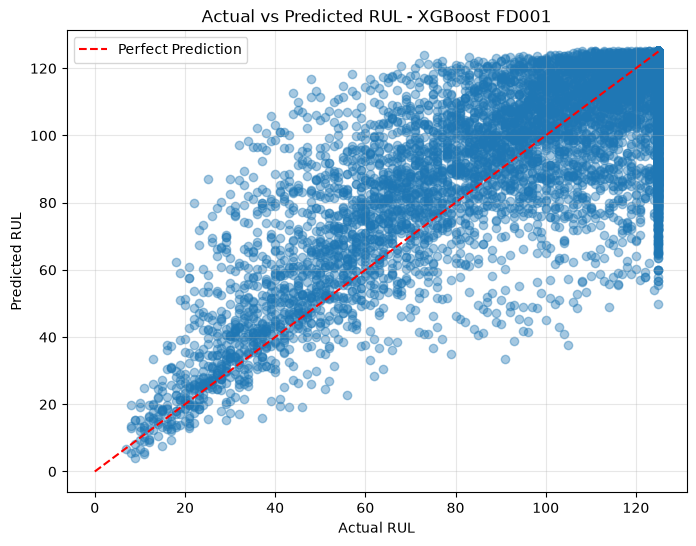

In [210]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_fd001,
    test_predictions_fd001,
    alpha=0.4
)

# Perfect prediction reference line
plt.plot(
    [0, 125],
    [0, 125],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - XGBoost FD001")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

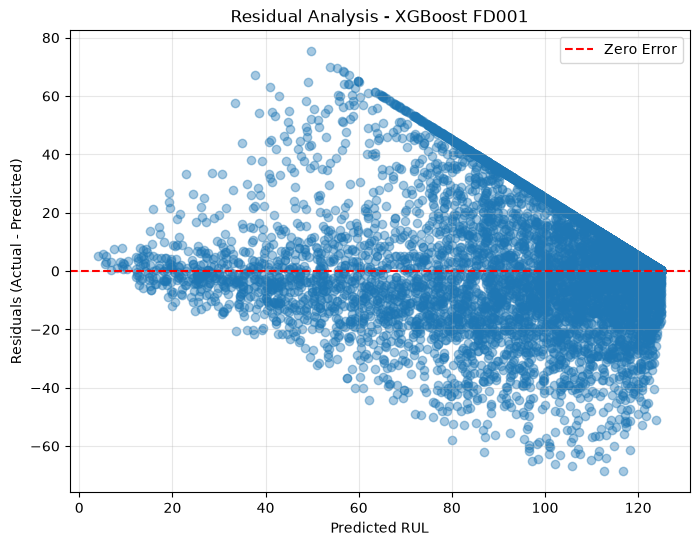

In [212]:
residuals_fd001 = y_test_fd001 - test_predictions_fd001

plt.figure(figsize=(8, 6))

plt.scatter(
    test_predictions_fd001,
    residuals_fd001,
    alpha=0.4
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - XGBoost FD001")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

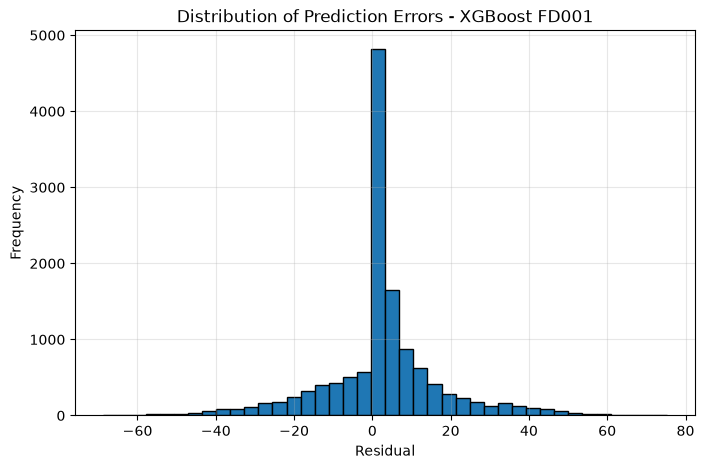

In [213]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals_fd001,
    bins=40,
    edgecolor='black'
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors - XGBoost FD001")
plt.grid(alpha=0.3)

plt.show()

In [214]:
# Uncapped RUL targets
y_train_uncapped_fd001 = df_fd001.loc[
    X_train_fd001.index, 'RUL'
]

y_val_uncapped_fd001 = df_fd001.loc[
    X_val_fd001.index, 'RUL'
]

print("Training target:", y_train_uncapped_fd001.shape)
print("Validation target:", y_val_uncapped_fd001.shape)

Training target: (16561,)
Validation target: (4070,)


In [215]:
uncapped_model_fd001 = XGBRegressor(
    n_estimators=700,
    learning_rate=0.01,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=5,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

uncapped_model_fd001.fit(
    X_train_fd001,
    y_train_uncapped_fd001
)

print("Uncapped FD001 model training completed.")

Uncapped FD001 model training completed.


In [216]:
# Predict on validation data
uncapped_val_predictions_fd001 = uncapped_model_fd001.predict(
    X_val_fd001
)

# Calculate validation metrics
uncapped_val_mae_fd001 = mean_absolute_error(
    y_val_uncapped_fd001,
    uncapped_val_predictions_fd001
)

uncapped_val_rmse_fd001 = np.sqrt(
    mean_squared_error(
        y_val_uncapped_fd001,
        uncapped_val_predictions_fd001
    )
)

uncapped_val_r2_fd001 = r2_score(
    y_val_uncapped_fd001,
    uncapped_val_predictions_fd001
)

print("FD001 Uncapped Validation Results")
print("---------------------------------")
print("MAE  :", round(uncapped_val_mae_fd001, 4))
print("RMSE :", round(uncapped_val_rmse_fd001, 4))
print("R2   :", round(uncapped_val_r2_fd001, 4))

FD001 Uncapped Validation Results
---------------------------------
MAE  : 23.2432
RMSE : 30.5122
R2   : 0.784


In [221]:
# Generate uncapped test predictions
uncapped_test_predictions_fd001 = uncapped_model_fd001.predict(
    X_test_fd001
)

print("Uncapped test predictions:",
      uncapped_test_predictions_fd001.shape)

Uncapped test predictions: (13096,)


In [223]:
# Prepare uncapped test target
y_test_uncapped_fd001 = test_fd001_processed['RUL']

# Predict using uncapped model
uncapped_test_predictions_fd001 = (
    uncapped_model_fd001.predict(X_test_fd001)
)

# Evaluate
uncapped_test_mae_fd001 = mean_absolute_error(
    y_test_uncapped_fd001,
    uncapped_test_predictions_fd001
)

uncapped_test_rmse_fd001 = np.sqrt(
    mean_squared_error(
        y_test_uncapped_fd001,
        uncapped_test_predictions_fd001
    )
)

uncapped_test_r2_fd001 = r2_score(
    y_test_uncapped_fd001,
    uncapped_test_predictions_fd001
)

print("FD001 Uncapped Test Results")
print("---------------------------")
print("MAE :", round(uncapped_test_mae_fd001, 4))
print("RMSE:", round(uncapped_test_rmse_fd001, 4))
print("R2  :", round(uncapped_test_r2_fd001, 4))

FD001 Uncapped Test Results
---------------------------
MAE : 31.4058
RMSE: 41.5673
R2  : 0.5033


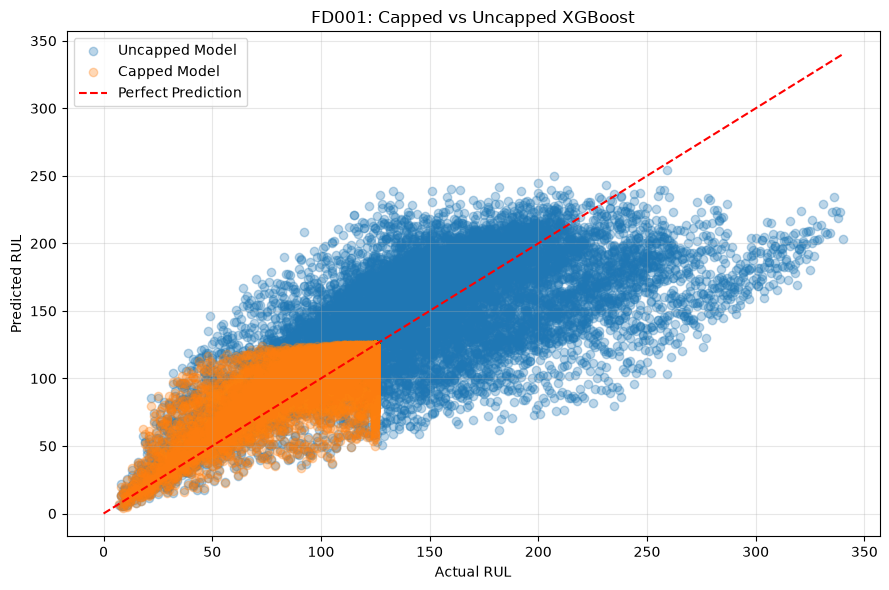

In [224]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test_uncapped_fd001,
    uncapped_test_predictions_fd001,
    alpha=0.3,
    label='Uncapped Model'
)

plt.scatter(
    y_test_fd001,
    test_predictions_fd001,
    alpha=0.3,
    label='Capped Model'
)

limit = max(y_test_uncapped_fd001.max(), 125)

plt.plot(
    [0, limit],
    [0, limit],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("FD001: Capped vs Uncapped XGBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [225]:
# Select the last observed cycle for each engine
last_cycle_fd001 = (
    test_fd001_processed
    .sort_values(['unit_number', 'time_in_cycles'])
    .groupby('unit_number')
    .tail(1)
    .copy()
)

# Prepare final-cycle features
X_final_fd001 = last_cycle_fd001[feature_columns_fd001]

# Predict using the capped model
final_predictions_fd001 = capped_model_fd001.predict(
    X_final_fd001
)

# Official RUL values
actual_final_rul_fd001 = rul_fd001['RUL'].to_numpy()

print("Number of engines:", len(final_predictions_fd001))
print("Actual RUL values:", len(actual_final_rul_fd001))
print("Predicted RUL values:", len(final_predictions_fd001))

Number of engines: 100
Actual RUL values: 100
Predicted RUL values: 100


In [228]:
errors_fd001 = (
    final_predictions_fd001 - actual_final_rul_fd001
)

scores_fd001 = np.where(
    errors_fd001 < 0,
    np.exp(-errors_fd001 / 13) - 1,
    np.exp(errors_fd001 / 10) - 1
)

nasa_score_fd001 = scores_fd001.sum()

print("FD001 NASA Score:", round(nasa_score_fd001, 4))
print("Average NASA Score:", round(scores_fd001.mean(), 4))

FD001 NASA Score: 611.4237
Average NASA Score: 6.1142


In [229]:
# Calculate final-cycle prediction errors
errors_fd001 = (
    final_predictions_fd001 - actual_final_rul_fd001
)

# Count prediction types
over_predictions_fd001 = np.sum(errors_fd001 > 0)
under_predictions_fd001 = np.sum(errors_fd001 < 0)
correct_predictions_fd001 = np.sum(errors_fd001 == 0)

print("Overestimations:", over_predictions_fd001)
print("Underestimations:", under_predictions_fd001)
print("Exact predictions:", correct_predictions_fd001)

# Average error magnitudes
print(
    "Average overestimation:",
    np.mean(errors_fd001[errors_fd001 > 0])
)

print(
    "Average underestimation:",
    np.mean(np.abs(errors_fd001[errors_fd001 < 0]))
)

Overestimations: 50
Underestimations: 50
Exact predictions: 0
Average overestimation: 13.06876859664917
Average underestimation: 15.379797048568726


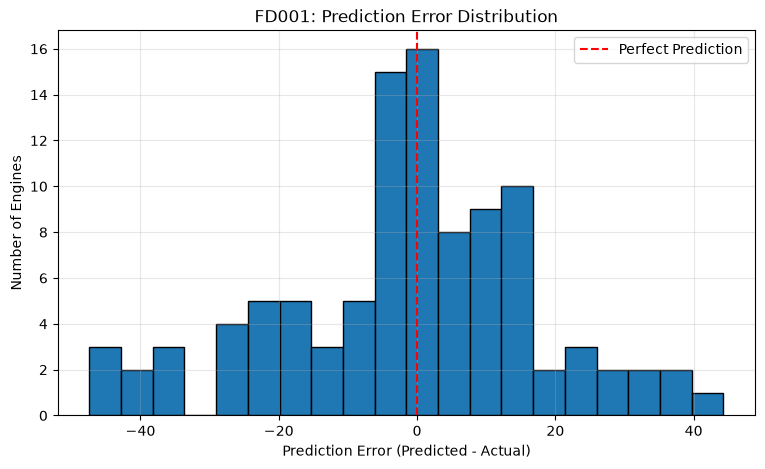

In [230]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(errors_fd001, bins=20, edgecolor='black')

plt.axvline(0, color='red', linestyle='--',
            label='Perfect Prediction')

plt.xlabel("Prediction Error (Predicted - Actual)")
plt.ylabel("Number of Engines")
plt.title("FD001: Prediction Error Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [231]:
# Create error analysis DataFrame
error_analysis_fd001 = pd.DataFrame({
    'Actual_RUL': actual_final_rul_fd001,
    'Predicted_RUL': final_predictions_fd001,
    'Error': errors_fd001,
    'NASA_Score': scores_fd001
})

# Sort by highest NASA penalty
error_analysis_fd001 = error_analysis_fd001.sort_values(
    by='NASA_Score',
    ascending=False
)

print(error_analysis_fd001.head(10))

    Actual_RUL  Predicted_RUL      Error  NASA_Score
40          18      62.306023  44.306023   82.981981
36          21      57.501282  36.501282   37.479598
88         136      88.603233 -47.396767   37.317439
66          77     112.752609  35.752609   34.703936
44         114      68.063683 -45.936317   33.245764
29         115      69.224556 -45.775444   32.824588
14          83     117.881981  34.881981   31.726924
17          28      60.993370  32.993370   26.094669
73         126      86.060783 -39.939217   20.590371
78          63      93.345016  30.345016   19.790614


In [233]:
# Select the final observation for each engine
final_test_fd001 = (
    test_fd001_processed
    .sort_values(['unit_number', 'time_in_cycles'])
    .groupby('unit_number')
    .tail(1)
    .sort_values('unit_number')
)

# Prepare final-cycle features
X_test_final_fd001 = final_test_fd001[feature_columns_fd001]

# Actual uncapped RUL from official file
y_test_final_fd001 = rul_fd001['RUL'].to_numpy()

# Predict using the capped FD001 model
final_predictions_fd001 = capped_model_fd001.predict(
    X_test_final_fd001
)

# Calculate prediction errors
final_errors_fd001 = (
    final_predictions_fd001 - y_test_final_fd001
)

# NASA scoring function
nasa_scores_fd001 = np.where(
    final_errors_fd001 < 0,
    np.exp(-final_errors_fd001 / 13) - 1,
    np.exp(final_errors_fd001 / 10) - 1
)

print("FD001 Final-Cycle Evaluation")
print("----------------------------")
print("Number of engines:", len(final_test_fd001))

print(
    "Final-cycle MAE:",
    round(mean_absolute_error(
        y_test_final_fd001,
        final_predictions_fd001
    ), 4)
)

print("NASA Score:", round(nasa_scores_fd001.sum(), 4))

FD001 Final-Cycle Evaluation
----------------------------
Number of engines: 100
Final-cycle MAE: 14.2243
NASA Score: 611.4237


In [234]:
error_analysis_fd001 = pd.DataFrame({
    'Engine_ID': final_test_fd001['unit_number'].to_numpy(),
    'Actual_RUL': y_test_final_fd001,
    'Predicted_RUL': final_predictions_fd001,
    'Error': final_errors_fd001,
    'NASA_Score': nasa_scores_fd001
})

worst_engines_fd001 = (
    error_analysis_fd001
    .sort_values('NASA_Score', ascending=False)
    .head(10)
)

print(worst_engines_fd001.to_string(index=False))

 Engine_ID  Actual_RUL  Predicted_RUL      Error  NASA_Score
        41          18      62.306023  44.306023   82.981981
        37          21      57.501282  36.501282   37.479598
        89         136      88.603233 -47.396767   37.317439
        67          77     112.752609  35.752609   34.703936
        45         114      68.063683 -45.936317   33.245764
        30         115      69.224556 -45.775444   32.824588
        15          83     117.881981  34.881981   31.726924
        18          28      60.993370  32.993370   26.094669
        74         126      86.060783 -39.939217   20.590371
        79          63      93.345016  30.345016   19.790614


In [235]:
# Identify sensor columns
sensor_cols_fd001 = [
    col for col in final_test_fd001.columns
    if col.startswith('sensor_')
]

# Merge worst-performing engines with sensor readings
worst_engine_sensors_fd001 = (
    worst_engines_fd001
    .merge(
        final_test_fd001[
            ['unit_number'] + sensor_cols_fd001
        ],
        left_on='Engine_ID',
        right_on='unit_number',
        how='left'
    )
)

# Display sensor readings
print(
    worst_engine_sensors_fd001[
        ['Engine_ID', 'Actual_RUL',
         'Predicted_RUL', 'Error'] + sensor_cols_fd001
    ].to_string(index=False)
)

 Engine_ID  Actual_RUL  Predicted_RUL      Error  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
        41          18      62.306023  44.306023    518.67    642.54   1594.24   1416.76     14.62     21.61    553.02   2388.19   9036.88        1.3      47.64     520.61    2388.20    8115.82     8.4533       0.03        395       2388      100.0      38.84    23.1718
        37          21      57.501282  36.501282    518.67    643.34   1593.15   1413.38     14.62     21.61    552.56   2388.18   9041.71        1.3      47.69     520.69    2388.15    8119.07     8.4944       0.03        394       2388      100.0      38.76    23.2145
        89         136      88.603233 -47.396767    518.67    642.91   1588.94   1407.43     14.62     21.61    553.18   2388.08   9057.58        1.3      47.36     521.47    2388.12    8

In [236]:
# Calculate sensor statistics
sensor_stats_fd001 = final_test_fd001[
    sensor_cols_fd001
].describe().T

sensor_stats_fd001['CV'] = (
    sensor_stats_fd001['std'] /
    sensor_stats_fd001['mean'].abs()
)

print(
    sensor_stats_fd001[
        ['mean', 'std', 'min', 'max', 'CV']
    ].sort_values('CV', ascending=False)
)

                  mean           std        min        max            CV
sensor_4   1410.548200  8.626344e+00  1389.3300  1428.4200  6.115597e-03
sensor_11    47.595100  2.569892e-01    47.0800    48.1300  5.399488e-03
sensor_3   1591.824700  6.646293e+00  1576.9300  1607.5500  4.175267e-03
sensor_21    23.259711  9.653015e-02    23.0242    23.4982  4.150101e-03
sensor_20    38.764800  1.559622e-01    38.3500    39.1900  4.023294e-03
sensor_15     8.452841  3.296393e-02     8.3732     8.5259  3.899746e-03
sensor_17   393.520000  1.466667e+00   390.0000   397.0000  3.727045e-03
sensor_9   9063.703400  2.199305e+01  9026.8900  9155.0300  2.426497e-03
sensor_14  8142.304200  1.862938e+01  8115.8200  8214.6400  2.287974e-03
sensor_7    553.148900  8.802914e-01   550.8800   555.0700  1.591418e-03
sensor_12   521.277000  6.975317e-01   519.4400   522.6500  1.338121e-03
sensor_2    642.768400  4.445920e-01   641.7500   644.0300  6.916831e-04
sensor_6     21.609900  1.000000e-03    21.6000    

In [237]:
# Identify 10 best-performing engines
best_engines_fd001 = (
    error_analysis_fd001
    .sort_values('NASA_Score', ascending=True)
    .head(10)
)

# Calculate average sensor readings for worst engines
worst_sensor_mean_fd001 = (
    worst_engine_sensors_fd001[sensor_cols_fd001]
    .mean()
)

# Get sensor readings for best engines
best_engine_sensors_fd001 = (
    best_engines_fd001
    .merge(
        final_test_fd001[
            ['unit_number'] + sensor_cols_fd001
        ],
        left_on='Engine_ID',
        right_on='unit_number',
        how='left'
    )
)

best_sensor_mean_fd001 = (
    best_engine_sensors_fd001[sensor_cols_fd001]
    .mean()
)

# Compare sensor means
sensor_comparison_fd001 = pd.DataFrame({
    'Worst_10_Mean': worst_sensor_mean_fd001,
    'Best_10_Mean': best_sensor_mean_fd001
})

sensor_comparison_fd001['Difference'] = (
    sensor_comparison_fd001['Worst_10_Mean'] -
    sensor_comparison_fd001['Best_10_Mean']
)

print(
    sensor_comparison_fd001
    .sort_values('Difference', key=abs, ascending=False)
)

           Worst_10_Mean  Best_10_Mean  Difference
sensor_9      9052.33800    9073.33300   -20.99500
sensor_14     8132.53200    8150.17000   -17.63800
sensor_4      1409.78200    1412.40500    -2.62300
sensor_17      393.50000     394.10000    -0.60000
sensor_3      1594.37600    1594.62400    -0.24800
sensor_2       642.70000     642.94000    -0.24000
sensor_7       553.27700     553.08900     0.18800
sensor_12      521.27200     521.12200     0.15000
sensor_11       47.52900      47.61000    -0.08100
sensor_20       38.79500      38.73000     0.06500
sensor_8      2388.13300    2388.11500     0.01800
sensor_21       23.27024      23.25261     0.01763
sensor_13     2388.13700    2388.12200     0.01500
sensor_15        8.44671       8.45229    -0.00558
sensor_1       518.67000     518.67000     0.00000
sensor_5        14.62000      14.62000     0.00000
sensor_6        21.61000      21.61000     0.00000
sensor_10        1.30000       1.30000     0.00000
sensor_16        0.03000       

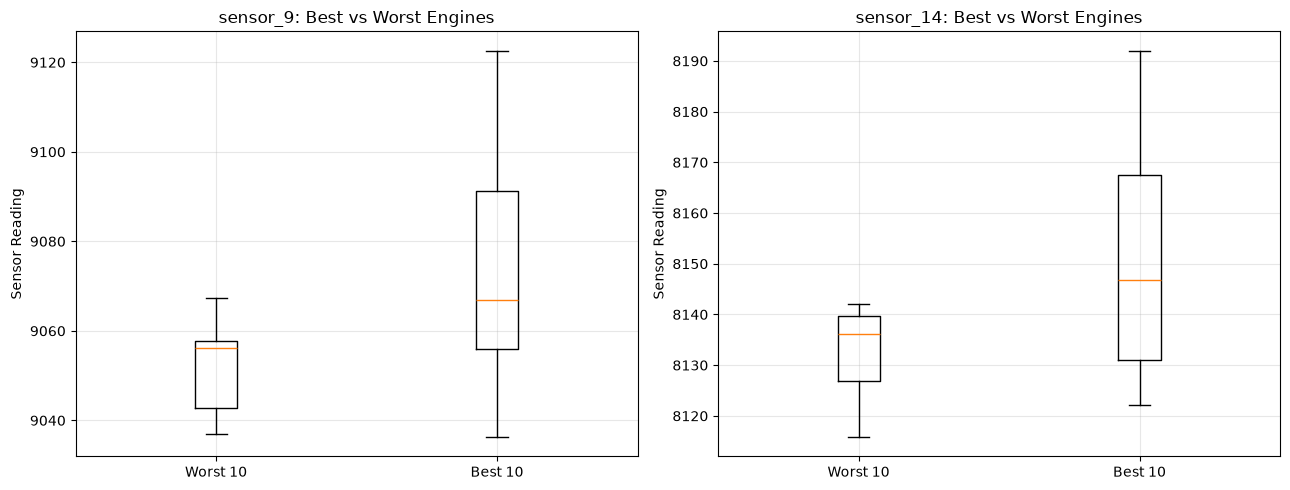

In [238]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sensor_compare = ['sensor_9', 'sensor_14']

for ax, sensor in zip(axes, sensor_compare):

    ax.boxplot(
        [
            worst_engine_sensors_fd001[sensor],
            best_engine_sensors_fd001[sensor]
        ],
        tick_labels=['Worst 10', 'Best 10']
    )

    ax.set_title(f'{sensor}: Best vs Worst Engines')
    ax.set_ylabel('Sensor Reading')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [240]:
# Combine final-cycle sensor readings with prediction errors
sensor_error_data_fd001 = final_test_fd001[
    ['unit_number'] + sensor_cols_fd001
].copy()

sensor_error_data_fd001['Abs_Error'] = np.abs(
    final_errors_fd001
)

sensor_error_data_fd001['Signed_Error'] = (
    final_errors_fd001
)

# Calculate Spearman correlation
sensor_error_corr_fd001 = (
    sensor_error_data_fd001[
        sensor_cols_fd001 + ['Abs_Error', 'Signed_Error']
    ]
    .corr(method='spearman')
)

# Show sensor correlations with absolute error
print(
    sensor_error_corr_fd001['Abs_Error']
    .drop(['Abs_Error', 'Signed_Error'])
    .sort_values(key=abs, ascending=False)
)

sensor_2    -0.280060
sensor_20    0.274211
sensor_11   -0.273503
sensor_4    -0.249289
sensor_17   -0.235548
sensor_9    -0.225491
sensor_14   -0.219334
sensor_21    0.214601
sensor_3    -0.213652
sensor_15   -0.196197
sensor_12    0.194479
sensor_7     0.145921
sensor_13   -0.075571
sensor_8    -0.075470
sensor_6     0.029595
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: Abs_Error, dtype: float64


In [241]:
# Sensor correlation with signed prediction errors
signed_corr_fd001 = (
    sensor_error_corr_fd001['Signed_Error']
    .drop(['Abs_Error', 'Signed_Error'])
    .sort_values(key=abs, ascending=False)
)

print("Sensor Correlation with Signed Errors")
print("-------------------------------------")
print(signed_corr_fd001)

Sensor Correlation with Signed Errors
-------------------------------------
sensor_15   -0.139341
sensor_4     0.124200
sensor_21   -0.102695
sensor_11    0.087136
sensor_6     0.078339
sensor_7     0.076894
sensor_8     0.068889
sensor_17   -0.066462
sensor_13    0.048716
sensor_2     0.041133
sensor_20   -0.026118
sensor_12    0.024796
sensor_14   -0.005221
sensor_9    -0.003708
sensor_3     0.000972
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: Signed_Error, dtype: float64


In [239]:
# Get the final observation of each engine
final_test_fd001 = (
    test_fd001_processed
    .sort_values(['unit_number', 'time_in_cycles'])
    .groupby('unit_number')
    .tail(1)
    .sort_values('unit_number')
)

# Prepare features
X_test_final_fd001 = final_test_fd001[feature_columns_fd001]

# Official uncapped RUL
y_test_final_fd001 = rul_fd001['RUL'].to_numpy()

# Generate predictions
final_predictions_fd001 = capped_model_fd001.predict(
    X_test_final_fd001
)

# Create comparison dataframe
results_fd001 = pd.DataFrame({
    'Engine': final_test_fd001['unit_number'].values,
    'Actual_RUL': y_test_final_fd001,
    'Predicted_RUL': final_predictions_fd001
})

# Calculate errors
results_fd001['Error'] = (
    results_fd001['Predicted_RUL'] -
    results_fd001['Actual_RUL']
)

results_fd001['Absolute_Error'] = (
    results_fd001['Error'].abs()
)

print(results_fd001.head(15))

    Engine  Actual_RUL  Predicted_RUL      Error  Absolute_Error
0        1         112     123.470535  11.470535       11.470535
1        2          98     122.532402  24.532402       24.532402
2        3          69      60.359020  -8.640980        8.640980
3        4          82      83.831001   1.831001        1.831001
4        5          91     102.712875  11.712875       11.712875
5        6          93      86.950775  -6.049225        6.049225
6        7          91     107.512947  16.512947       16.512947
7        8          95      66.349426 -28.650574       28.650574
8        9         111     121.966621  10.966621       10.966621
9       10          96     110.344353  14.344353       14.344353
10      11          97      79.961586 -17.038414       17.038414
11      12         124      98.571861 -25.428139       25.428139
12      13          95     101.679840   6.679840        6.679840
13      14         107     121.756561  14.756561       14.756561
14      15          83   

In [242]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate final-cycle metrics
mae_fd001 = mean_absolute_error(
    y_test_final_fd001,
    final_predictions_fd001
)

rmse_fd001 = np.sqrt(
    mean_squared_error(
        y_test_final_fd001,
        final_predictions_fd001
    )
)

r2_fd001 = r2_score(
    y_test_final_fd001,
    final_predictions_fd001
)

print("FD001 Final-Cycle Test Results")
print("--------------------------------")
print("MAE :", round(mae_fd001, 4))
print("RMSE:", round(rmse_fd001, 4))
print("R2  :", round(r2_fd001, 4))

FD001 Final-Cycle Test Results
--------------------------------
MAE : 14.2243
RMSE: 18.8926
R2  : 0.7933


In [243]:
print("Final test records:", len(final_test_fd001))
print("Unique engines:", final_test_fd001['unit_number'].nunique())

print("Feature count:", X_test_final_fd001.shape[1])
print("Actual RUL count:", len(y_test_final_fd001))
print("Prediction count:", len(final_predictions_fd001))

print("Model:", type(capped_model_fd001).__name__)

Final test records: 100
Unique engines: 100
Feature count: 19
Actual RUL count: 100
Prediction count: 100
Model: XGBRegressor


In [244]:
# Best 5 predictions (lowest absolute error)
print("Best 5 FD001 Predictions:")
print(
    results_fd001.nsmallest(5, 'Absolute_Error')
)

# Worst 5 predictions (highest absolute error)
print("\nWorst 5 FD001 Predictions:")
print(
    results_fd001.nlargest(5, 'Absolute_Error')
)

Best 5 FD001 Predictions:
    Engine  Actual_RUL  Predicted_RUL     Error  Absolute_Error
87      88         115     115.175446  0.175446        0.175446
33      34           7       6.711076 -0.288924        0.288924
58      59         114     114.318634  0.318634        0.318634
39      40          28      27.591997 -0.408003        0.408003
31      32          48      48.569511  0.569511        0.569511

Worst 5 FD001 Predictions:
    Engine  Actual_RUL  Predicted_RUL      Error  Absolute_Error
88      89         136      88.603233 -47.396767       47.396767
44      45         114      68.063683 -45.936317       45.936317
29      30         115      69.224556 -45.775444       45.775444
40      41          18      62.306023  44.306023       44.306023
73      74         126      86.060783 -39.939217       39.939217


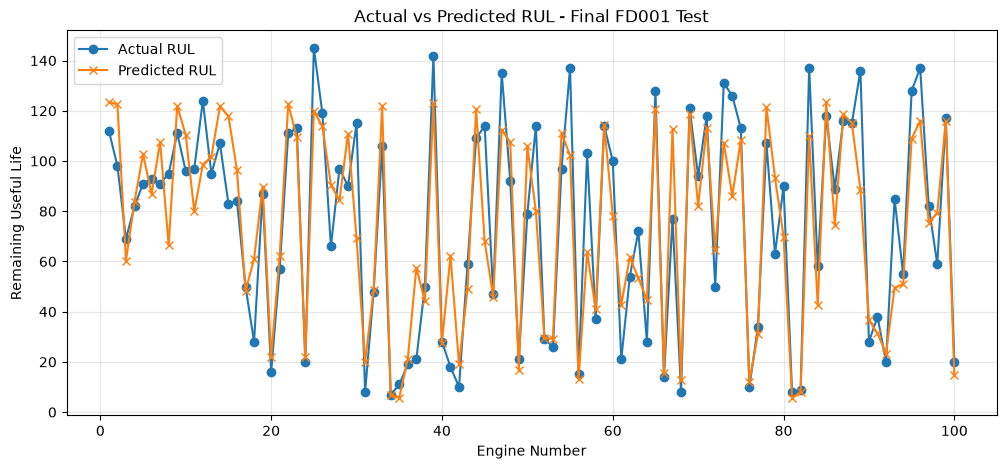

In [246]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    results_fd001['Engine'],
    results_fd001['Actual_RUL'],
    label='Actual RUL',
    marker='o'
)

plt.plot(
    results_fd001['Engine'],
    results_fd001['Predicted_RUL'],
    label='Predicted RUL',
    marker='x'
)

plt.xlabel("Engine Number")
plt.ylabel("Remaining Useful Life")
plt.title("Actual vs Predicted RUL - Final FD001 Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

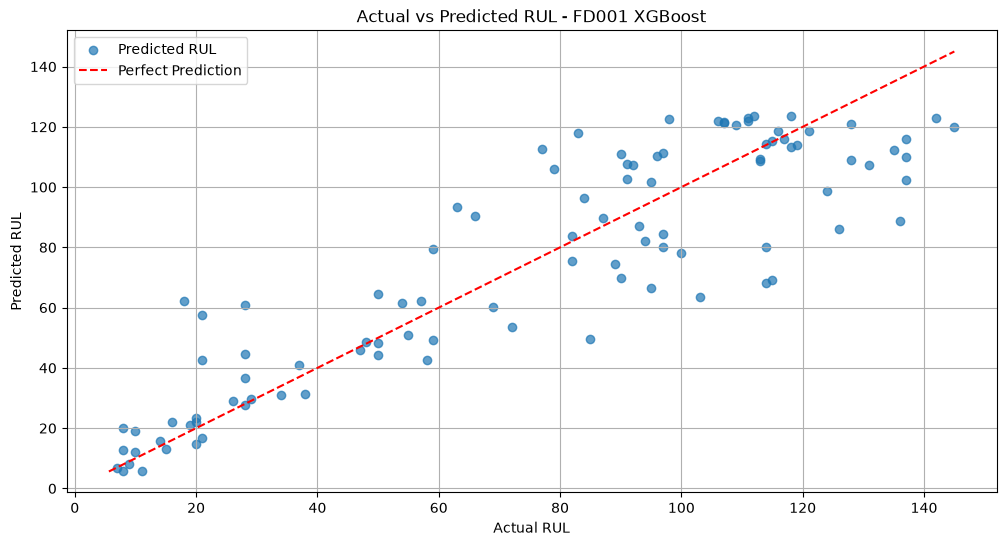

In [247]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.scatter(
    y_test_final_fd001,
    final_predictions_fd001,
    alpha=0.7,
    label='Predicted RUL'
)

# Perfect prediction reference line
min_value = min(y_test_final_fd001.min(), final_predictions_fd001.min())
max_value = max(y_test_final_fd001.max(), final_predictions_fd001.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL - FD001 XGBoost')
plt.legend()
plt.grid(True)
plt.show()

In [248]:
# Original uncapped RUL
y_uncapped_fd001 = df_fd001['RUL']

# Use the same train-validation split
y_train_uncapped_fd001 = y_uncapped_fd001.iloc[train_idx_fd001]
y_val_uncapped_fd001 = y_uncapped_fd001.iloc[val_idx_fd001]

print("Training shape:", y_train_uncapped_fd001.shape)
print("Validation shape:", y_val_uncapped_fd001.shape)

print("\nUncapped RUL Statistics:")
print(y_uncapped_fd001.describe())

Training shape: (16561,)
Validation shape: (4070,)

Uncapped RUL Statistics:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [249]:
from xgboost import XGBRegressor

# Initialize uncapped XGBoost model
uncapped_model_fd001 = XGBRegressor(
    n_estimators=700,
    learning_rate=0.01,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=5,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train the model using uncapped RUL
uncapped_model_fd001.fit(
    X_train_fd001,
    y_train_uncapped_fd001
)

print("FD001 Uncapped XGBoost Training Completed!")

FD001 Uncapped XGBoost Training Completed!


In [250]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict on validation data
uncapped_val_pred_fd001 = uncapped_model_fd001.predict(
    X_val_fd001
)

# Calculate metrics
uncapped_val_mae_fd001 = mean_absolute_error(
    y_val_uncapped_fd001,
    uncapped_val_pred_fd001
)

uncapped_val_rmse_fd001 = np.sqrt(
    mean_squared_error(
        y_val_uncapped_fd001,
        uncapped_val_pred_fd001
    )
)

uncapped_val_r2_fd001 = r2_score(
    y_val_uncapped_fd001,
    uncapped_val_pred_fd001
)

print("FD001 Uncapped Validation Results")
print("---------------------------------")
print("MAE :", round(uncapped_val_mae_fd001, 4))
print("RMSE:", round(uncapped_val_rmse_fd001, 4))
print("R2  :", round(uncapped_val_r2_fd001, 4))

FD001 Uncapped Validation Results
---------------------------------
MAE : 23.2432
RMSE: 30.5122
R2  : 0.784


In [254]:
# Predict using uncapped model
# Predict using uncapped model
uncapped_final_predictions = uncapped_model_fd001.predict(
    X_test_final_fd001
)

# Evaluate
uncapped_test_mae = mean_absolute_error(
    y_test_final_fd001,
    uncapped_final_predictions
)

uncapped_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_final_fd001,
        uncapped_final_predictions
    )
)

uncapped_test_r2 = r2_score(
    y_test_final_fd001,
    uncapped_final_predictions
)

print("Uncapped Final Test MAE:", uncapped_test_mae)
print("Uncapped Final Test RMSE:", uncapped_test_rmse)
print("Uncapped Final Test R2:", uncapped_test_r2)

# Evaluate
uncapped_test_mae = mean_absolute_error(
    y_test_final_fd001,
    uncapped_final_predictions
)

uncapped_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_final_fd001,
        uncapped_final_predictions
    )
)

uncapped_test_r2 = r2_score(
    y_test_final_fd001,
    uncapped_final_predictions
)

print("Uncapped Final Test MAE:", uncapped_test_mae)
print("Uncapped Final Test RMSE:", uncapped_test_rmse)
print("Uncapped Final Test R2:", uncapped_test_r2)

Uncapped Final Test MAE: 19.14344024658203
Uncapped Final Test RMSE: 26.284267764835942
Uncapped Final Test R2: 0.5999334454536438
Uncapped Final Test MAE: 19.14344024658203
Uncapped Final Test RMSE: 26.284267764835942
Uncapped Final Test R2: 0.5999334454536438


In [255]:
# Capped model NASA score
capped_errors_fd001 = (
    final_predictions_fd001 - actual_final_rul_fd001
)

capped_scores_fd001 = np.where(
    capped_errors_fd001 < 0,
    np.exp(-capped_errors_fd001 / 13) - 1,
    np.exp(capped_errors_fd001 / 10) - 1
)

# Uncapped model final-cycle predictions
uncapped_final_predictions_fd001 = (
    uncapped_model_fd001.predict(X_test_final_fd001)
)

# Uncapped model NASA score
uncapped_errors_fd001 = (
    uncapped_final_predictions_fd001 - actual_final_rul_fd001
)

uncapped_scores_fd001 = np.where(
    uncapped_errors_fd001 < 0,
    np.exp(-uncapped_errors_fd001 / 13) - 1,
    np.exp(uncapped_errors_fd001 / 10) - 1
)

print("Capped NASA Score:", round(capped_scores_fd001.sum(), 4))
print("Uncapped NASA Score:", round(uncapped_scores_fd001.sum(), 4))

Capped NASA Score: 611.4237
Uncapped NASA Score: 5913.5753


In [256]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create metrics comparison
metrics_fd001 = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2'],
    'Capped Model': [
        mean_absolute_error(y_test_fd001, test_predictions_fd001),
        np.sqrt(mean_squared_error(y_test_fd001, test_predictions_fd001)),
        r2_score(y_test_fd001, test_predictions_fd001)
    ],
    'Uncapped Model': [
        mean_absolute_error(
            y_test_uncapped_fd001,
            uncapped_test_predictions_fd001
        ),
        np.sqrt(mean_squared_error(
            y_test_uncapped_fd001,
            uncapped_test_predictions_fd001
        )),
        r2_score(
            y_test_uncapped_fd001,
            uncapped_test_predictions_fd001
        )
    ]
})

print("FD001 MODEL PERFORMANCE COMPARISON")
print(metrics_fd001.round(4).to_string(index=False))

print("\nNASA SCORE COMPARISON")
print("Capped:", round(nasa_scores_fd001.sum(), 4))
print("Uncapped:", round(uncapped_scores_fd001.sum(), 4))

print("\nFINAL-CYCLE PERFORMANCE")
print("MAE:", round(mae_fd001, 4))
print("RMSE:", round(rmse_fd001, 4))
print("R2:", round(r2_fd001, 4))

FD001 MODEL PERFORMANCE COMPARISON
Metric  Capped Model  Uncapped Model
   MAE       10.0040         31.4058
  RMSE       15.7706         41.5673
    R2        0.6730          0.5033

NASA SCORE COMPARISON
Capped: 611.4237
Uncapped: 5913.5753

FINAL-CYCLE PERFORMANCE
MAE: 14.2243
RMSE: 18.8926
R2: 0.7933


In [257]:
print("Capped model:", type(capped_model_fd001))

print("\nNumber of model features:",
      capped_model_fd001.n_features_in_)

print("Number of training features:",
      len(feature_columns_fd001))

print("\nFeature columns:")
print(feature_columns_fd001)

Capped model: <class 'xgboost.sklearn.XGBRegressor'>

Number of model features: 19
Number of training features: 19

Feature columns:
['time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


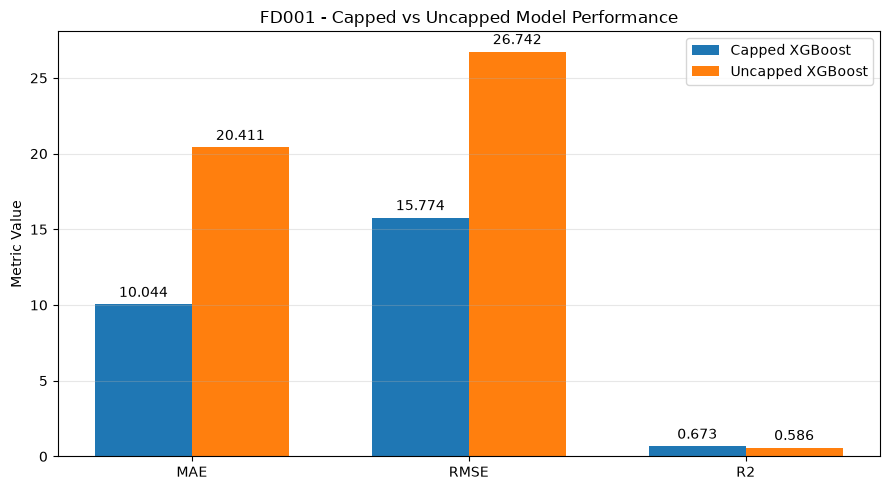

In [258]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

metrics = ['MAE', 'RMSE', 'R2']

capped_values = [ 
    10.0436,
    15.7737,
    0.6729
]

uncapped_values = [
    20.4112,
    26.7420,
    0.5859
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width/2,
    capped_values,
    width,
    label='Capped XGBoost'
)

bars2 = ax.bar(
    x + width/2,
    uncapped_values,
    width,
    label='Uncapped XGBoost'
)

ax.set_ylabel("Metric Value")
ax.set_title("FD001 - Capped vs Uncapped Model Performance")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(axis='y', alpha=0.3)

ax.bar_label(bars1, fmt='%.3f', padding=3)
ax.bar_label(bars2, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

In [259]:
import pickle
import os

os.makedirs("../models", exist_ok=True)

with open("../models/xgboost_fd001_capped.pkl", "wb") as file:
    pickle.dump(capped_model_fd001, file)

print("FD001 model saved successfully!")

FD001 model saved successfully!


In [260]:
print("File exists:",
      os.path.exists("../models/xgboost_fd001_capped.pkl"))

print("File size:",
      round(os.path.getsize("../models/xgboost_fd001_capped.pkl") / 1024, 2),
      "KB")

File exists: True
File size: 7421.59 KB


In [263]:
feature_columns_fd001 = [
    'time_in_cycles',
    'op_setting_1', 'op_setting_2', 'op_setting_3',
    'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6',
    'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11',
    'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
    'sensor_17', 'sensor_20', 'sensor_21'
]

model_config = {
    "features": feature_columns_fd001,
    "model_type": "XGBoost",
    "dataset": "NASA C-MAPSS FD001",
    "target": "RUL_cap125",
    "rul_cap": 125
}

In [264]:
print("Number of features:", len(model_config["features"]))

with open("../models/model_config.pkl", "wb") as file:
    pickle.dump(model_config, file)

print("Configuration saved successfully!")

Number of features: 19
Configuration saved successfully!


In [267]:
# Select the final-cycle records using the saved feature order
sample = final_test_fd001[loaded_config["features"]].iloc[[0]]

# Predict
prediction = loaded_model.predict(sample)

# Apply RUL cap
prediction = prediction.clip(0, loaded_config["rul_cap"])

print("Predicted RUL:", round(float(prediction[0]), 2))

Predicted RUL: 123.47
